ПЕРВИЧНЫЙ АНАЛИЗ ДАННЫХ

Размерность данных: 288 наблюдений × 3 переменных

Период: с 2000-01 по 2023-12

Описательные статистики:
              CPI             M2    Key_Rate
count  288.000000     288.000000  288.000000
mean     9.667014   45883.229861   11.993056
std      4.530222   48709.333600    5.635405
min      2.200000    1331.900000    4.250000
25%      6.200000    7302.225000    8.000000
50%      8.850000   27834.400000   11.000000
75%     12.625000   67585.075000   15.000000
max     20.500000  200829.500000   25.000000

Пропущенные значения:
CPI         0
M2          0
Key_Rate    0
Year        0
dtype: int64


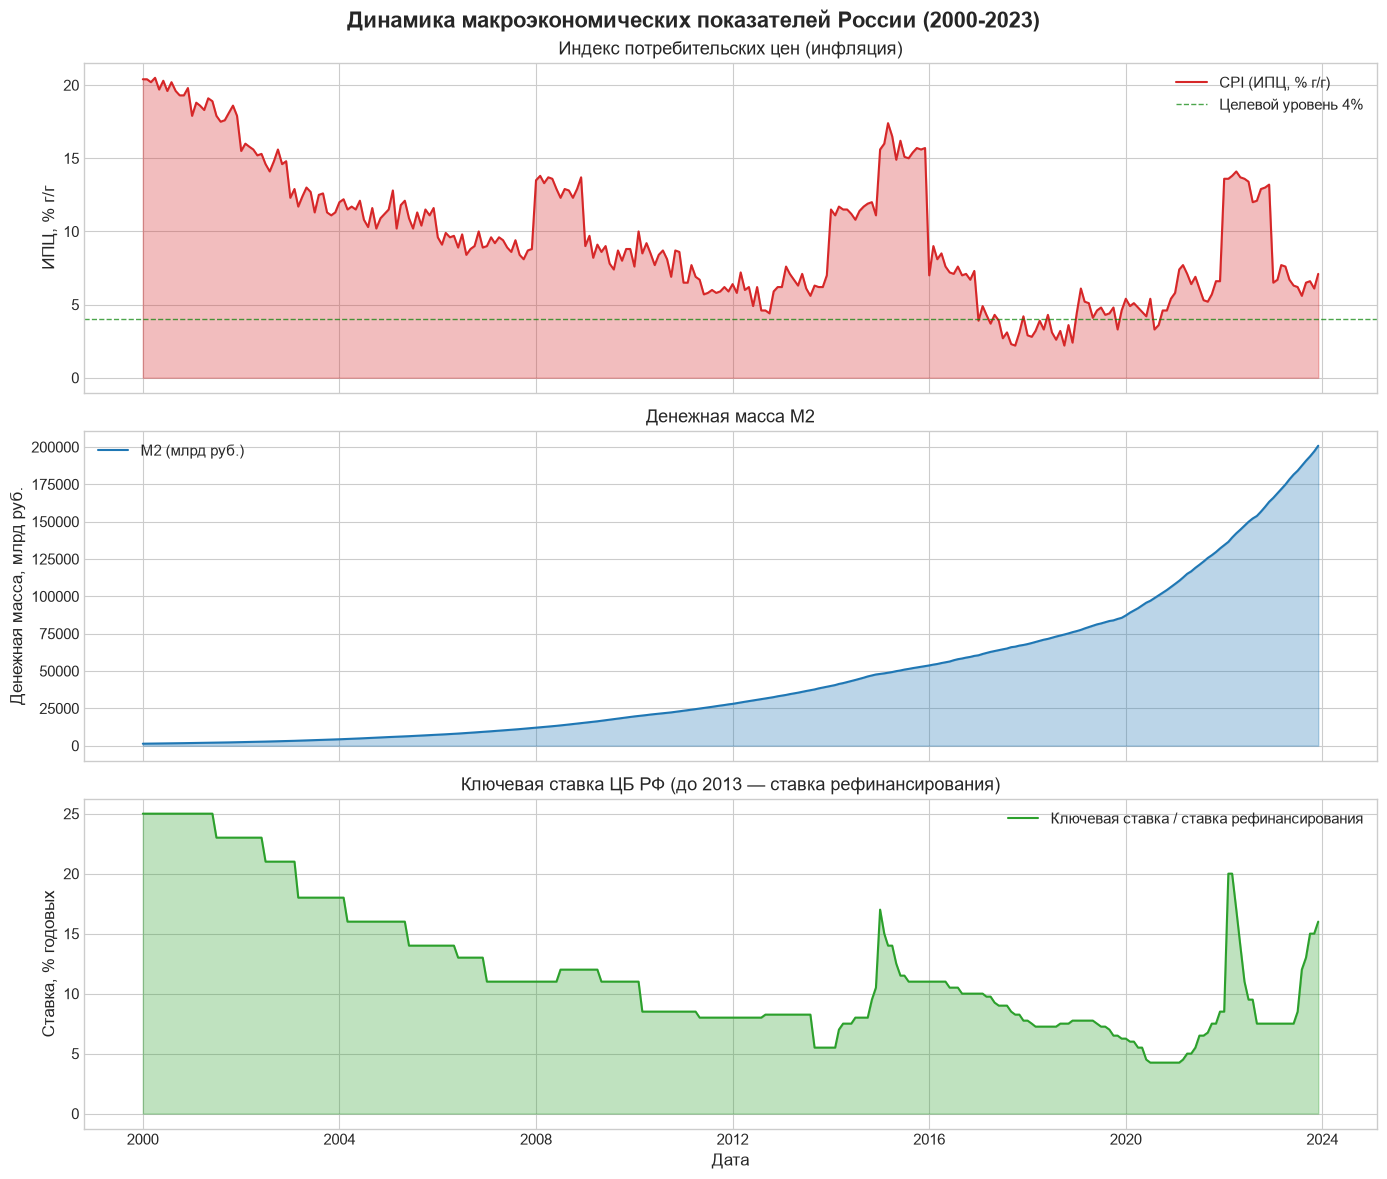

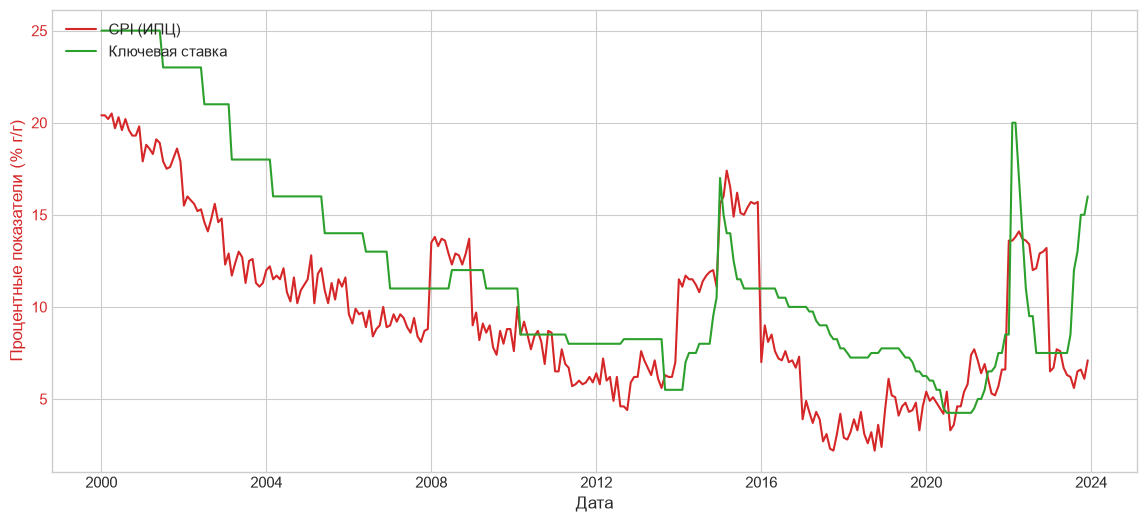

In [2]:
# =============================================================================
# БАЗОВЫЙ ВИЗУАЛЬНЫЙ АНАЛИЗ МАКРОЭКОНОМИЧЕСКИХ ДАННЫХ РФ (2000-2023)
# =============================================================================

# 1. ИМПОРТ БИБЛИОТЕК
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings('ignore')

# Настройка стиля графиков
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# 2. ЗАГРУЗКА ДАННЫХ
# Предположим, что CSV файл сохранён в текущей директории
df = pd.read_csv('macro_data_2000_2023.csv')

# Преобразуем столбец даты в формат datetime и устанавливаем как индекс
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m')
df.set_index('Date', inplace=True)

# Создаём столбец с годом для удобства группировки
df['Year'] = df.index.year

print("=" * 60)
print("ПЕРВИЧНЫЙ АНАЛИЗ ДАННЫХ")
print("=" * 60)
print(f"\nРазмерность данных: {df.shape[0]} наблюдений × {df.shape[1] - 1} переменных")
print(f"\nПериод: с {df.index.min().strftime('%Y-%m')} по {df.index.max().strftime('%Y-%m')}")
print(f"\nОписательные статистики:")
print(df[['CPI', 'M2', 'Key_Rate']].describe())
print(f"\nПропущенные значения:\n{df.isnull().sum()}")

# =============================================================================
# ГРАФИК 1: УРОВНИ ВРЕМЕННЫХ РЯДОВ (3 подграфика)
# =============================================================================
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
fig.suptitle('Динамика макроэкономических показателей России (2000-2023)', 
             fontsize=16, fontweight='bold', y=0.98)

# CPI
axes[0].plot(df.index, df['CPI'], color='#d62728', linewidth=1.5, label='CPI (ИПЦ, % г/г)')
axes[0].fill_between(df.index, df['CPI'], alpha=0.3, color='#d62728')
axes[0].set_ylabel('ИПЦ, % г/г', fontsize=12)
axes[0].set_title('Индекс потребительских цен (инфляция)', fontsize=13)
axes[0].legend(loc='upper right')
axes[0].axhline(y=4.0, color='green', linestyle='--', linewidth=1, alpha=0.7, label='Целевой уровень 4%')
axes[0].legend(loc='upper right')

# M2
axes[1].plot(df.index, df['M2'], color='#1f77b4', linewidth=1.5, label='M2 (млрд руб.)')
axes[1].fill_between(df.index, df['M2'], alpha=0.3, color='#1f77b4')
axes[1].set_ylabel('Денежная масса, млрд руб.', fontsize=12)
axes[1].set_title('Денежная масса M2', fontsize=13)
axes[1].legend(loc='upper left')

# Key Rate
axes[2].plot(df.index, df['Key_Rate'], color='#2ca02c', linewidth=1.5, label='Ключевая ставка / ставка рефинансирования')
axes[2].fill_between(df.index, df['Key_Rate'], alpha=0.3, color='#2ca02c')
axes[2].set_ylabel('Ставка, % годовых', fontsize=12)
axes[2].set_xlabel('Дата', fontsize=12)
axes[2].set_title('Ключевая ставка ЦБ РФ (до 2013 — ставка рефинансирования)', fontsize=13)
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.savefig('01_time_series_levels.png', dpi=300, bbox_inches='tight')
plt.show()

# =============================================================================
# ГРАФИК 2: СОВМЕСТНАЯ ДИНАМИКА (двойная ось Y)
# =============================================================================
fig, ax1 = plt.subplots(figsize=(14, 6))

color1 = '#d62728'
color2 = '#2ca02c'
color3 = '#1f77b4'

ax1.set_xlabel('Дата', fontsize=12)
ax1.set_ylabel('Процентные показатели (% г/г)', color=color1, fontsize=12)
ax1.plot(df.index, df['CPI'], color=color1, linewidth=1.5, label='CPI (ИПЦ)')
ax1.plot(df.index, df['Key_Rate'], color=color2, linewidth=1.5, label='Ключевая ставка')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.legend(loc='upper left')

# Вторая ось Y для M


АНАЛИЗ СТАЦИОНАРНОСТИ МАКРОЭКОНОМИЧЕСКИХ РЯДОВ

######################################################################
ПРОВЕРКА СТАЦИОНАРНОСТИ: CPI
######################################################################

Результаты ADF теста: CPI (уровень)
Статистика теста:       -2.654954
p-value:                0.082163
Количество лагов:       1
Количество наблюдений:  286

Критические значения:
  1%: -3.453423
  5%: -2.871699
  10%: -2.572183

✗ РЯД НЕ СТАЦИОНАРЕН (p-value >= 0.05)


Результаты ADF теста: CPI (разность 1)
Статистика теста:       -20.998224
p-value:                0.000000
Количество лагов:       0
Количество наблюдений:  286

Критические значения:
  1%: -3.453423
  5%: -2.871699
  10%: -2.572183

✓ РЯД СТАЦИОНАРЕН (p-value < 0.05)

→ Достигнута стационарность! Порядок интегрированности: I(1)

######################################################################
ПРОВЕРКА СТАЦИОНАРНОСТИ: M2
######################################################################

Резул

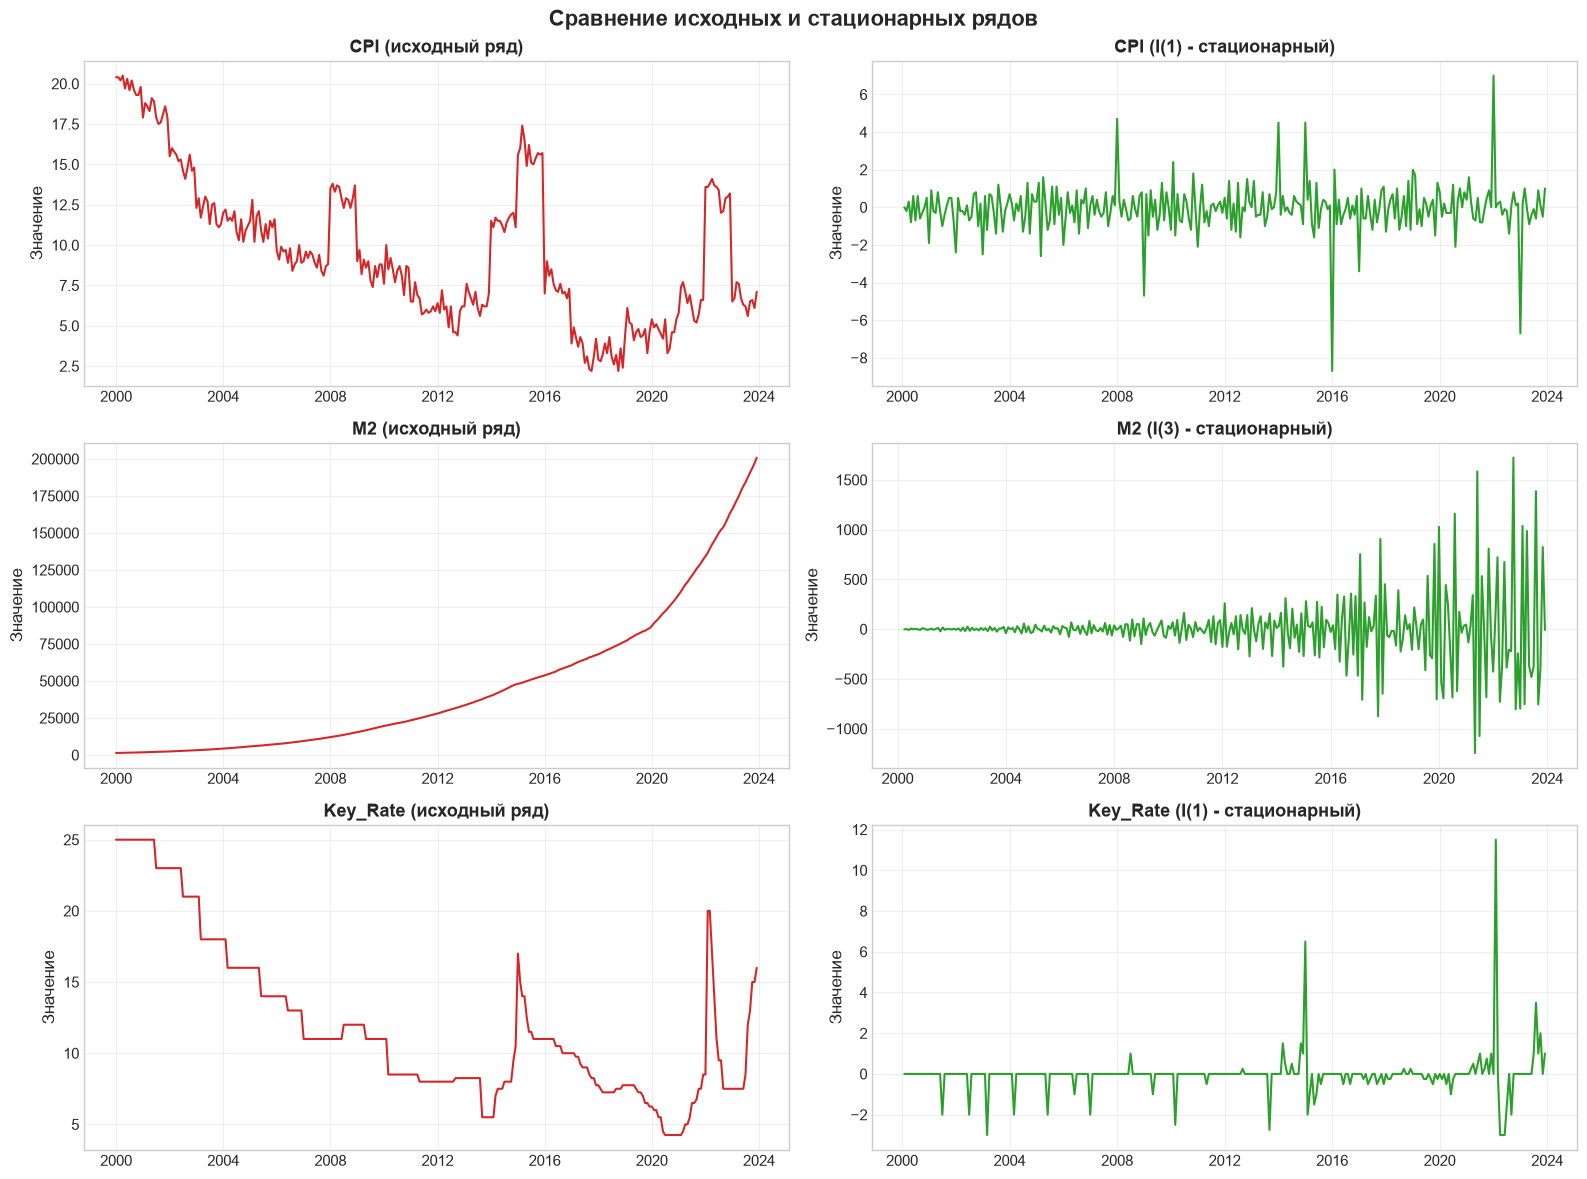

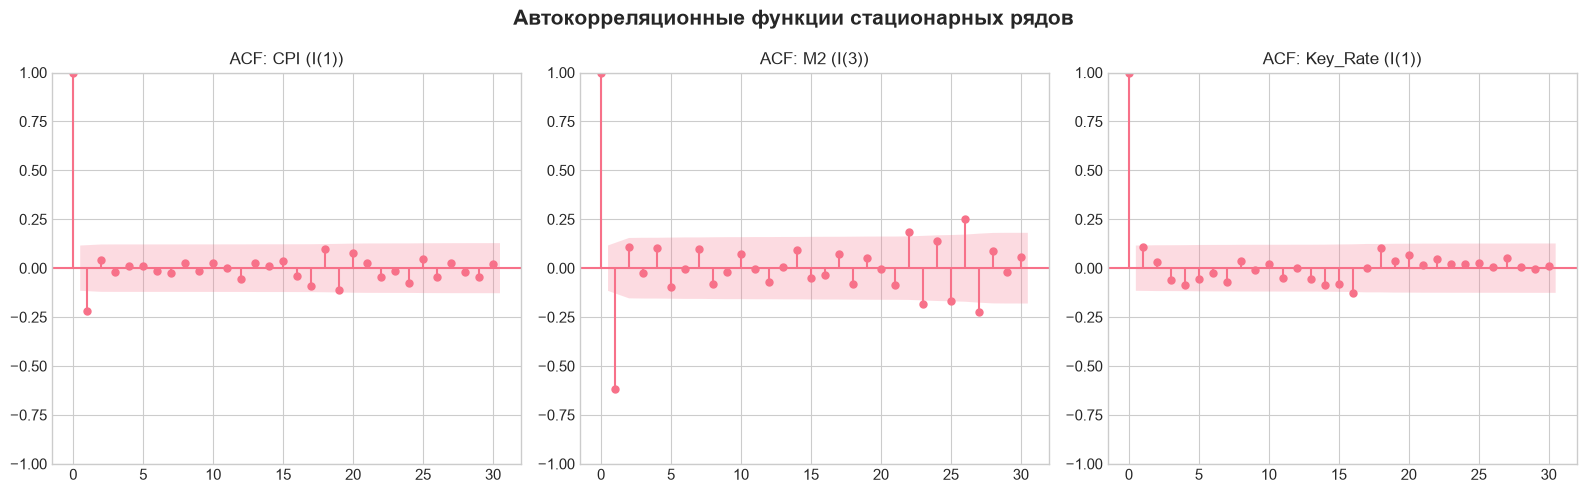


РЕЗУЛЬТАТЫ СОХРАНЕНЫ
✓ Стационарные ряды сохранены в: stationary_data.csv
✓ Графики сохранены:
  - stationarity_comparison.png
  - stationary_acf.png

Переменные для дальнейшей работы:
  - CPI_stationary, M2_stationary, Key_Rate_stationary
  - CPI_diff_order, M2_diff_order, Key_Rate_diff_order
  - stationary_data (словарь)
  - integration_orders (словарь)

ПРОВЕРКА СОЗДАННЫХ ПЕРЕМЕННЫХ

CPI_stationary: 287 наблюдений, порядок I(1)
M2_stationary: 285 наблюдений, порядок I(3)
Key_Rate_stationary: 287 наблюдений, порядок I(1)

Пример данных CPI_stationary:
Date
2000-02-01    0.0
2000-03-01   -0.2
2000-04-01    0.3
2000-05-01   -0.8
2000-06-01    0.6
2000-07-01   -0.7
2000-08-01    0.6
2000-09-01   -0.6
2000-10-01   -0.3
2000-11-01    0.0
Name: CPI, dtype: float64


In [3]:
# =============================================================================
# ПРОВЕРКА СТАЦИОНАРНОСТИ И ДИФФЕРЕНЦИРОВАНИЕ ВРЕМЕННЫХ РЯДОВ
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings('ignore')

# Настройка стиля
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)

# =============================================================================
# ФУНКЦИЯ 1: РАСШИРЕННЫЙ ТЕСТ ДИКИ-ФУЛЛЕРА (ADF)
# =============================================================================
def adf_test(series, title='', significance_level=0.05):
    """
    Проводит расширенный тест Дики-Фуллера для проверки стационарности.
    
    Параметры:
    -----------
    series : pandas.Series
        Временной ряд для проверки
    title : str
        Название ряда для вывода
    significance_level : float
        Уровень значимости (по умолчанию 0.05)
    
    Возвращает:
    -----------
    dict : Словарь с результатами теста
    """
    result = adfuller(series.dropna(), autolag='AIC')
    
    output = {
        'title': title,
        'test_statistic': result[0],
        'p_value': result[1],
        'lags_used': result[2],
        'n_obs': result[3],
        'critical_values': result[4],
        'is_stationary': result[1] < significance_level
    }
    
    return output


def print_adf_result(result):
    """Красивый вывод результатов ADF теста"""
    print(f"\n{'='*70}")
    print(f"Результаты ADF теста: {result['title']}")
    print(f"{'='*70}")
    print(f"Статистика теста:       {result['test_statistic']:.6f}")
    print(f"p-value:                {result['p_value']:.6f}")
    print(f"Количество лагов:       {result['lags_used']}")
    print(f"Количество наблюдений:  {result['n_obs']}")
    print(f"\nКритические значения:")
    for key, value in result['critical_values'].items():
        print(f"  {key}: {value:.6f}")
    
    if result['is_stationary']:
        print(f"\n✓ РЯД СТАЦИОНАРЕН (p-value < 0.05)")
    else:
        print(f"\n✗ РЯД НЕ СТАЦИОНАРЕН (p-value >= 0.05)")
    print(f"{'='*70}\n")


# =============================================================================
# ФУНКЦИЯ 2: ИТЕРАТИВНОЕ ДИФФЕРЕНЦИРОВАНИЕ ДО СТАЦИОНАРНОСТИ
# =============================================================================
def make_stationary(series, title='', max_diff=3, significance_level=0.05, verbose=True):
    """
    Итеративно дифференцирует ряд до достижения стационарности.
    
    Параметры:
    -----------
    series : pandas.Series
        Исходный временной ряд
    title : str
        Название ряда
    max_diff : int
        Максимальный порядок дифференцирования (по умолчанию 3)
    significance_level : float
        Уровень значимости для ADF теста
    verbose : bool
        Выводить ли подробную информацию
    
    Возвращает:
    -----------
    tuple : (стационарный ряд, порядок дифференцирования, список результатов ADF)
    """
    current_series = series.copy()
    diff_order = 0
    adf_results = []
    
    if verbose:
        print(f"\n{'#'*70}")
        print(f"ПРОВЕРКА СТАЦИОНАРНОСТИ: {title}")
        print(f"{'#'*70}")
    
    # Проверяем исходный ряд
    result = adf_test(current_series, f"{title} (уровень)", significance_level)
    adf_results.append(result)
    
    if verbose:
        print_adf_result(result)
    
    # Если уже стационарен - возвращаем
    if result['is_stationary']:
        if verbose:
            print(f"→ Ряд уже стационарен! Порядок интегрированности: I(0)")
        return current_series, diff_order, adf_results
    
    # Итеративное дифференцирование
    for d in range(1, max_diff + 1):
        current_series = current_series.diff().dropna()
        diff_order = d
        
        result = adf_test(current_series, f"{title} (разность {d})", significance_level)
        adf_results.append(result)
        
        if verbose:
            print_adf_result(result)
        
        # Если достигли стационарности - выходим
        if result['is_stationary']:
            if verbose:
                print(f"→ Достигнута стационарность! Порядок интегрированности: I({d})")
            return current_series, diff_order, adf_results
    
    # Если не достигли стационарности
    if verbose:
        print(f"⚠ ВНИМАНИЕ: Не удалось достичь стационарности за {max_diff} итераций!")
        print(f"→ Последний порядок интегрированности: I({diff_order})")
    
    return current_series, diff_order, adf_results


# =============================================================================
# ПРИМЕНЕНИЕ К ДАННЫМ
# =============================================================================
print("\n" + "="*70)
print("АНАЛИЗ СТАЦИОНАРНОСТИ МАКРОЭКОНОМИЧЕСКИХ РЯДОВ")
print("="*70)

# Словарь для хранения результатов
stationary_data = {}
integration_orders = {}
adf_reports = {}

# Обрабатываем каждый ряд
for col in ['CPI', 'M2', 'Key_Rate']:
    stationary_series, diff_order, adf_results = make_stationary(
        df[col], 
        title=col, 
        max_diff=3, 
        significance_level=0.05, 
        verbose=True
    )
    
    # Сохраняем результаты
    stationary_data[col] = stationary_series
    integration_orders[col] = diff_order
    adf_reports[col] = adf_results
    
    # Создаем имена переменных для удобства
    globals()[f'{col}_stationary'] = stationary_series
    globals()[f'{col}_diff_order'] = diff_order

# =============================================================================
# ИТОГОВЫЙ ОТЧЁТ О ПОРЯДКАХ ИНТЕГРИРОВАННОСТИ
# =============================================================================
print("\n" + "="*70)
print("ИТОГОВЫЙ ОТЧЁТ: ПОРЯДКИ ИНТЕГРИРОВАННОСТИ")
print("="*70)
for col in ['CPI', 'M2', 'Key_Rate']:
    print(f"{col:10s} → I({integration_orders[col]})")
print("="*70)

# =============================================================================
# ВИЗУАЛИЗАЦИЯ: ОРИГИНАЛЬНЫЕ vs СТАЦИОНАРНЫЕ РЯДЫ
# =============================================================================
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle('Сравнение исходных и стационарных рядов', 
             fontsize=16, fontweight='bold', y=0.98)

for i, col in enumerate(['CPI', 'M2', 'Key_Rate']):
    # Оригинальный ряд
    axes[i, 0].plot(df.index, df[col], color='#d62728', linewidth=1.5)
    axes[i, 0].set_title(f'{col} (исходный ряд)', fontsize=13, fontweight='bold')
    axes[i, 0].set_ylabel('Значение')
    axes[i, 0].grid(True, alpha=0.3)
    
    # Стационарный ряд
    axes[i, 1].plot(stationary_data[col].index, stationary_data[col], 
                    color='#2ca02c', linewidth=1.5)
    axes[i, 1].set_title(f'{col} (I({integration_orders[col]}) - стационарный)', 
                         fontsize=13, fontweight='bold')
    axes[i, 1].set_ylabel('Значение')
    axes[i, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('stationarity_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# =============================================================================
# ВИЗУАЛИЗАЦИЯ: ACF ДЛЯ СТАЦИОНАРНЫХ РЯДОВ
# =============================================================================
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Автокорреляционные функции стационарных рядов', 
             fontsize=15, fontweight='bold')

for i, col in enumerate(['CPI', 'M2', 'Key_Rate']):
    plot_acf(stationary_data[col], lags=30, ax=axes[i], alpha=0.05)
    axes[i].set_title(f'ACF: {col} (I({integration_orders[col]}))', fontsize=12)

plt.tight_layout()
plt.savefig('stationary_acf.png', dpi=300, bbox_inches='tight')
plt.show()

# =============================================================================
# СОХРАНЕНИЕ СТАЦИОНАРНЫХ ДАННЫХ В CSV
# =============================================================================
# Создаем DataFrame со стационарными рядами
stationary_df = pd.DataFrame({
    'CPI_stationary': stationary_data['CPI'],
    'M2_stationary': stationary_data['M2'],
    'Key_Rate_stationary': stationary_data['Key_Rate']
})

# Сохраняем в CSV
stationary_df.to_csv('stationary_data.csv', index=True)

print("\n" + "="*70)
print("РЕЗУЛЬТАТЫ СОХРАНЕНЫ")
print("="*70)
print("✓ Стационарные ряды сохранены в: stationary_data.csv")
print("✓ Графики сохранены:")
print("  - stationarity_comparison.png")
print("  - stationary_acf.png")
print("\nПеременные для дальнейшей работы:")
print("  - CPI_stationary, M2_stationary, Key_Rate_stationary")
print("  - CPI_diff_order, M2_diff_order, Key_Rate_diff_order")
print("  - stationary_data (словарь)")
print("  - integration_orders (словарь)")
print("="*70)

# =============================================================================
# ПРОВЕРОКА ДОСТУПНОСТИ ПЕРЕМЕННЫХ
# =============================================================================
print("\n" + "="*70)
print("ПРОВЕРКА СОЗДАННЫХ ПЕРЕМЕННЫХ")
print("="*70)
print(f"\nCPI_stationary: {len(CPI_stationary)} наблюдений, порядок I({CPI_diff_order})")
print(f"M2_stationary: {len(M2_stationary)} наблюдений, порядок I({M2_diff_order})")
print(f"Key_Rate_stationary: {len(Key_Rate_stationary)} наблюдений, порядок I({Key_Rate_diff_order})")

print("\nПример данных CPI_stationary:")
print(CPI_stationary.head(10))
print("="*70)

ПОДГОТОВКА ДАННЫХ ДЛЯ VAR-МОДЕЛИ

Размерность данных для VAR: (285, 3)
Период: с 2000-04-01 00:00:00 по 2023-12-01 00:00:00
Переменные: ['CPI', 'M2', 'Key_Rate']

Первые 5 наблюдений:
            CPI   M2  Key_Rate
Date                          
2000-04-01  0.3 -1.9       0.0
2000-05-01 -0.8  1.4       0.0
2000-06-01  0.6 -7.7       0.0
2000-07-01 -0.7  6.3       0.0
2000-08-01  0.6 -1.7       0.0

Описательные статистики:
              CPI           M2    Key_Rate
count  285.000000   285.000000  285.000000
mean    -0.045965     1.473333   -0.031579
std      1.274296   339.415421    1.017610
min     -8.700000 -1243.600000   -3.000000
25%     -0.600000   -65.400000    0.000000
50%      0.000000     1.400000    0.000000
75%      0.600000    51.700000    0.000000
max      7.000000  1722.900000   11.500000

ОПРЕДЕЛЕНИЕ ОПТИМАЛЬНОГО ПОРЯДКА ЛАГА (p)

Результаты выбора порядка лага:
 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------

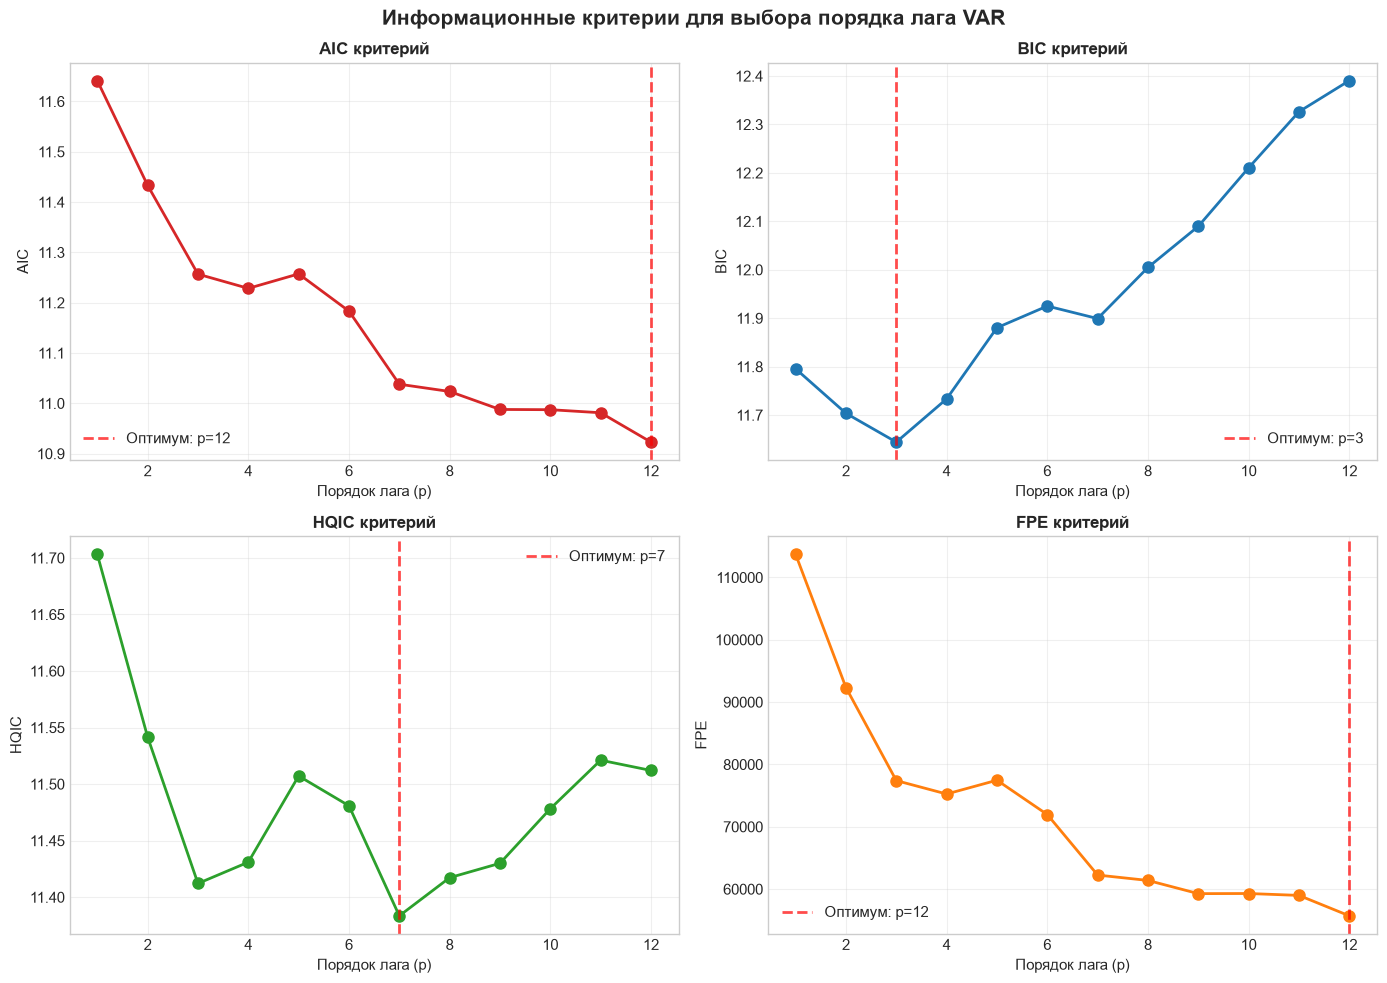


ПОСТРОЕНИЕ VAR-МОДЕЛИ С ПОРЯДКОМ ЛАГА p = 12

РЕЗУЛЬТАТЫ ОЦЕНКИ VAR-МОДЕЛИ
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 08, Oct, 2026
Time:                     20:34:41
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                    12.3905
Nobs:                     273.000    HQIC:                   11.5120
Log likelihood:          -2542.09    FPE:                    55712.6
AIC:                      10.9229    Det(Omega_mle):         38050.2
--------------------------------------------------------------------
Results for equation CPI
                  coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------------
const               -0.040739         0.075984           -0.536           0.592
L1.CPI              -0.266792         0.064584           -4.131       

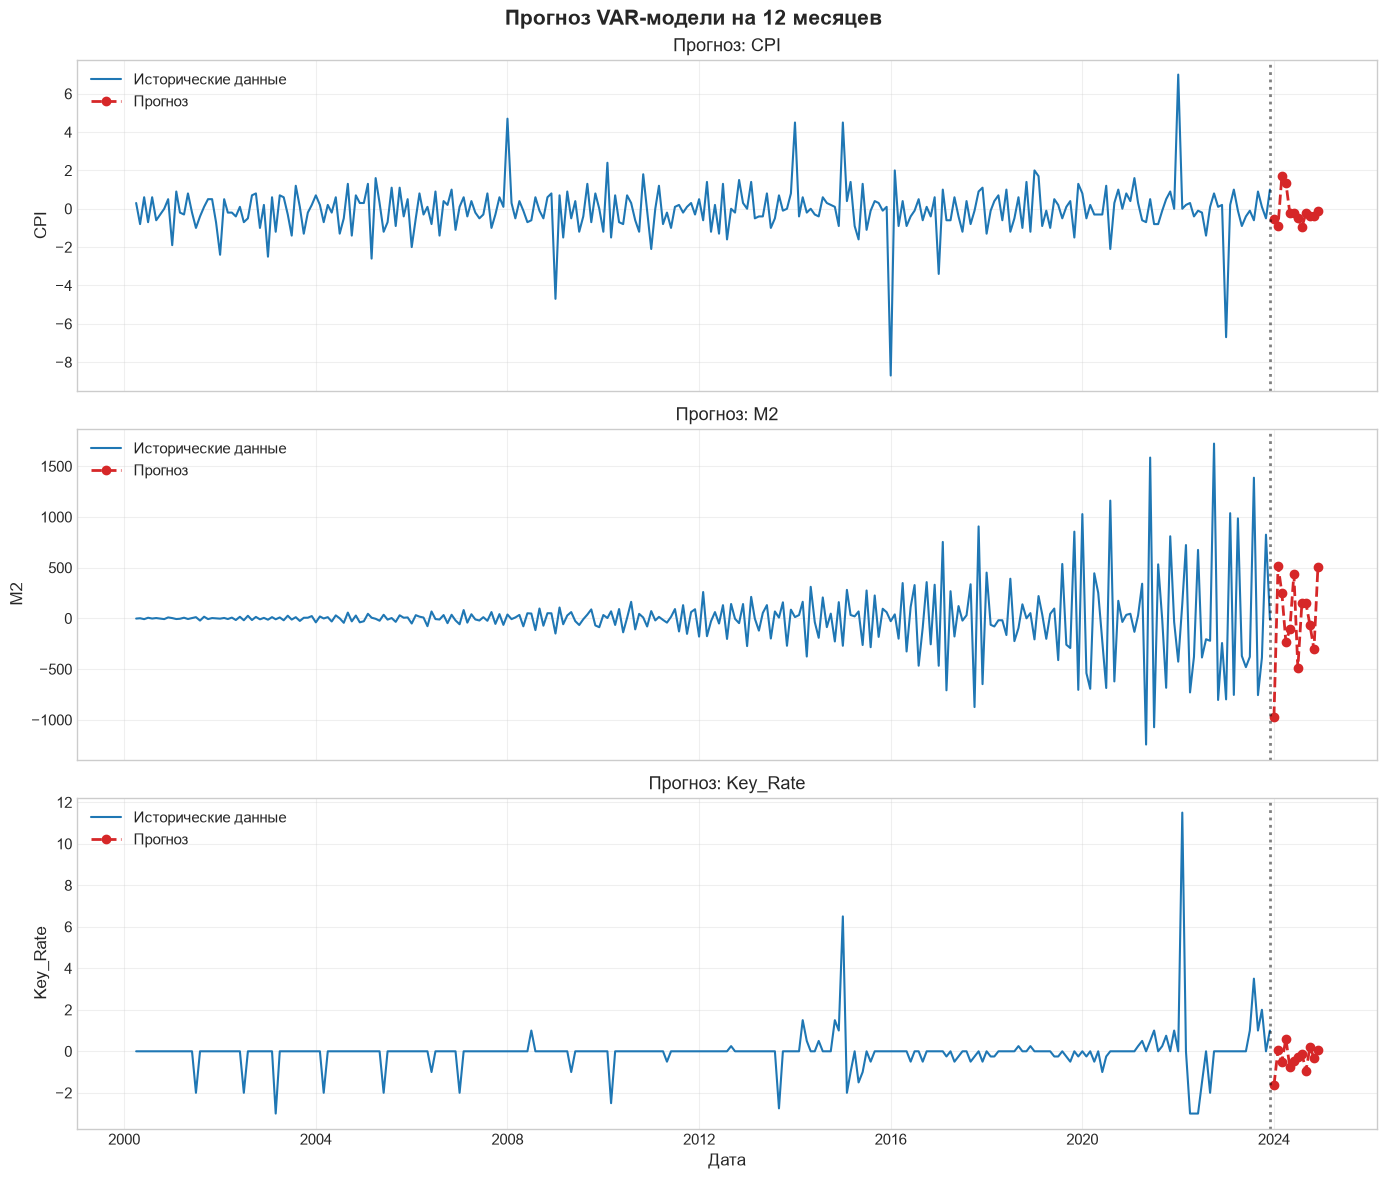

In [24]:
# =============================================================================
# ПОСТРОЕНИЕ VAR-МОДЕЛИ С ОПТИМИЗАЦИЕЙ ПОРЯДКА ЛАГА
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.vector_ar.var_model import VAR
from statsmodels.tsa.stattools import adfuller
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Настройка стиля
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

# =============================================================================
# ШАГ 1: ПОДГОТОВКА ДАННЫХ ДЛЯ VAR-МОДЕЛИ
# =============================================================================
print("="*70)
print("ПОДГОТОВКА ДАННЫХ ДЛЯ VAR-МОДЕЛИ")
print("="*70)

# Создаем DataFrame со стационарными рядами
var_data = pd.DataFrame({
    'CPI': stationary_data['CPI'],
    'M2': stationary_data['M2'],
    'Key_Rate': stationary_data['Key_Rate']
})

# Удаляем пропуски (могут появиться после дифференцирования)
var_data = var_data.dropna()

# Сохраняем имена переменных отдельно (для совместимости с любой версией statsmodels)
endog_names = list(var_data.columns)

print(f"\nРазмерность данных для VAR: {var_data.shape}")
print(f"Период: с {var_data.index.min()} по {var_data.index.max()}")
print(f"Переменные: {endog_names}")
print(f"\nПервые 5 наблюдений:")
print(var_data.head())
print(f"\nОписательные статистики:")
print(var_data.describe())

# =============================================================================
# ШАГ 2: ОПРЕДЕЛЕНИЕ ОПТИМАЛЬНОГО ПОРЯДКА ЛАГА
# =============================================================================
print("\n" + "="*70)
print("ОПРЕДЕЛЕНИЕ ОПТИМАЛЬНОГО ПОРЯДКА ЛАГА (p)")
print("="*70)

# Создаем модель VAR
model = VAR(var_data)

# Максимальное количество лагов для проверки
max_lags = 12

# Используем встроенный метод select_order
lag_selection = model.select_order(maxlags=max_lags)

# Выводим полную таблицу результатов
print("\nРезультаты выбора порядка лага:")
print(lag_selection.summary())

# Извлекаем рекомендуемые лаги напрямую из атрибутов объекта
recommended_lags = {
    'AIC': lag_selection.aic,
    'BIC': lag_selection.bic,
    'HQIC': lag_selection.hqic,
    'FPE': lag_selection.fpe
}

print("\n" + "="*70)
print("ОПТИМАЛЬНЫЕ ПОРЯДКИ ЛАГА ПО РАЗЛИЧНЫМ КРИТЕРИЯМ")
print("="*70)
for criterion, lag in recommended_lags.items():
    print(f"{criterion:6s}: p = {lag}")

# Выбираем наиболее часто встречающийся оптимальный лаг
most_common_lag = Counter(recommended_lags.values()).most_common(1)[0][0]
print(f"\n✓ РЕКОМЕНДУЕМЫЙ ПОРЯДОК ЛАГА: p = {most_common_lag}")
print(f"  (выбран на основе большинства критериев)")

# =============================================================================
# ВИЗУАЛИЗАЦИЯ ИНФОРМАЦИОННЫХ КРИТЕРИЕВ
# =============================================================================
criteria_data = []
for lag in range(1, max_lags + 1):
    try:
        temp_model = model.fit(maxlags=lag)
        criteria_data.append({
            'Lag': lag,
            'AIC': temp_model.aic,
            'BIC': temp_model.bic,
            'HQIC': temp_model.hqic,
            'FPE': temp_model.fpe
        })
    except Exception as e:
        print(f"Предупреждение: не удалось оценить модель с лагом {lag}: {e}")
        continue

criteria_df = pd.DataFrame(criteria_data)
criteria_df.set_index('Lag', inplace=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Информационные критерии для выбора порядка лага VAR', 
             fontsize=15, fontweight='bold')

criteria_names_list = ['AIC', 'BIC', 'HQIC', 'FPE']
colors = ['#d62728', '#1f77b4', '#2ca02c', '#ff7f0e']

for i, (criterion, color) in enumerate(zip(criteria_names_list, colors)):
    ax = axes[i // 2, i % 2]
    ax.plot(criteria_df.index, criteria_df[criterion], 
            marker='o', linewidth=2, markersize=8, color=color)
    ax.axvline(recommended_lags[criterion], color='red', 
               linestyle='--', linewidth=2, alpha=0.7,
               label=f'Оптимум: p={recommended_lags[criterion]}')
    ax.set_xlabel('Порядок лага (p)', fontsize=11)
    ax.set_ylabel(criterion, fontsize=11)
    ax.set_title(f'{criterion} критерий', fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('var_lag_selection.png', dpi=300, bbox_inches='tight')
plt.show()

# =============================================================================
# ШАГ 3: ПОСТРОЕНИЕ ФИНАЛЬНОЙ VAR-МОДЕЛИ
# =============================================================================
print("\n" + "="*70)
print(f"ПОСТРОЕНИЕ VAR-МОДЕЛИ С ПОРЯДКОМ ЛАГА p = {most_common_lag}")
print("="*70)

# Оцениваем финальную модель
var_result = model.fit(maxlags=most_common_lag, ic='aic')

print("\n" + "="*70)
print("РЕЗУЛЬТАТЫ ОЦЕНКИ VAR-МОДЕЛИ")
print("="*70)
print(var_result.summary())

# =============================================================================
# ШАГ 4: АНАЛИЗ КОЭФФИЦИЕНТОВ МОДЕЛИ (ИСПРАВЛЕННЫЙ)
# =============================================================================
print("\n" + "="*70)
print("КОЭФФИЦИЕНТЫ МОДЕЛИ ПО УРАВНЕНИЯМ")
print("="*70)

# Получаем имена экзогенных переменных
try:
    exog_names = var_result.model.exog_names
except AttributeError:
    # Генерируем имена вручную
    n_lags = most_common_lag
    n_vars = len(var_names)
    exog_names = ['const']
    for lag in range(1, n_lags + 1):
        for vname in var_names:
            exog_names.append(f'L{lag}.{vname}')

# ИСПРАВЛЕНИЕ: преобразуем в numpy-массивы перед индексацией
params_array = np.array(var_result.params)
pvalues_array = np.array(var_result.pvalues)

for i, endog_name in enumerate(var_names):
    print(f"\n{'='*70}")
    print(f"УРАВНЕНИЕ ДЛЯ {endog_name}")
    print(f"{'='*70}")
    
    # Теперь используем numpy-массивы
    params = params_array[:, i]
    pvalues = pvalues_array[:, i]
    
    print(f"\n{'Переменная':<20} {'Коэффициент':>12} {'p-value':>12} {'Значимость':>12}")
    print("-" * 70)
    
    for j, (param, pval) in enumerate(zip(params, pvalues)):
        var_name = exog_names[j] if j < len(exog_names) else f'var_{j}'
        significance = "***" if pval < 0.01 else "**" if pval < 0.05 else "*" if pval < 0.1 else ""
        print(f"{var_name:<20} {param:>12.6f} {pval:>12.4f} {significance:>12}")
    
    print("\nУровень значимости: *** p<0.01, ** p<0.05, * p<0.1")

# =============================================================================
# ПРОГНОЗИРОВАНИЕ
# =============================================================================
print("\n" + "="*70)
print("ПРОГНОЗИРОВАНИЕ НА 12 МЕСЯЦЕВ ВПЕРЕД")
print("="*70)

# Прогноз на 12 месяцев
forecast_steps = 12
forecast = var_result.forecast(var_data.values, steps=forecast_steps)

# ИСПРАВЛЕНИЕ: используем endog_names вместо var_data.endog_names
forecast_df = pd.DataFrame(
    forecast,
    index=pd.date_range(start=var_data.index[-1] + pd.DateOffset(months=1), 
                        periods=forecast_steps, freq='MS'),
    columns=endog_names
)

print("\nПрогноз значений:")
print(forecast_df.round(4))

# Визуализация прогноза
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
fig.suptitle(f'Прогноз VAR-модели на {forecast_steps} месяцев', 
             fontsize=15, fontweight='bold')

for i, col in enumerate(endog_names):
    # Исторические данные
    axes[i].plot(var_data.index, var_data[col], 
                 color='#1f77b4', linewidth=1.5, label='Исторические данные')
    
    # Прогноз
    axes[i].plot(forecast_df.index, forecast_df[col], 
                 color='#d62728', linewidth=2, linestyle='--', 
                 marker='o', markersize=6, label='Прогноз')
    
    # Вертикальная линия разделения
    axes[i].axvline(var_data.index[-1], color='black', 
                    linestyle=':', linewidth=2, alpha=0.5)
    
    axes[i].set_ylabel(col, fontsize=12)
    axes[i].set_title(f'Прогноз: {col}', fontsize=13)
    axes[i].legend(loc='best')
    axes[i].grid(True, alpha=0.3)

axes[2].set_xlabel('Дата', fontsize=12)
plt.tight_layout()
plt.savefig('var_forecast.png', dpi=300, bbox_inches='tight')
plt.show()

In [25]:
# =============================================================================
# ДИАГНОСТИКА VAR-МОДЕЛИ (УНИВЕРСАЛЬНАЯ ВЕРСИЯ)
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("ДИАГНОСТИКА VAR-МОДЕЛИ")
print("="*80)

# =============================================================================
# 1. ТЕСТ НА АВТОКОРРЕЛЯЦИЮ ОСТАТКОВ (МНОГОМЕРНЫЙ ТЕСТ ЛЮНГА-БОКСА)
# =============================================================================
print("\n1. Тест на автокорреляцию остатков (Тест Льюнга-Бокса)")
print("-" * 80)

# Универсальная функция для теста на автокорреляцию
def test_autocorrelation(var_result, nlags=12):
    """
    Проводит тест Льюнга-Бокса для многомерных остатков VAR-модели.
    Работает в любой версии statsmodels.
    """
    # Пробуем встроенные методы
    methods_to_try = [
        ('test_acorr', {'nlags': nlags}),
        ('test_whiteness', {'nlags': nlags}),
    ]
    
    for method_name, kwargs in methods_to_try:
        if hasattr(var_result, method_name):
            try:
                method = getattr(var_result, method_name)
                result = method(**kwargs)
                return result, f"Использован метод: {method_name}()"
            except Exception:
                continue
    
    # Если встроенные методы не работают, реализуем тест вручную
    print("Встроенные методы недоступны. Реализуем тест Льюнга-Бокса вручную...")
    
    # Извлекаем остатки
    residuals = np.array(var_result.resid)
    n_obs, n_vars = residuals.shape
    
    # Вычисляем автоковариационные матрицы
    cov_matrices = []
    for lag in range(nlags + 1):
        if lag == 0:
            # Ковариационная матрица для лага 0
            cov_mat = np.dot(residuals.T, residuals) / n_obs
        else:
            # Кросс-ковариационная матрица для лага k
            cov_mat = np.dot(residuals[lag:].T, residuals[:-lag]) / n_obs
        cov_matrices.append(cov_mat)
    
    # Ковариационная матрица для лага 0 (обратная)
    cov_0_inv = np.linalg.inv(cov_matrices[0])
    
    # Вычисляем статистику теста Льюнга-Бокса
    # Q = T * sum_{k=1}^{h} tr(C_k' * C_0^{-1} * C_k * C_0^{-1})
    Q_stat = 0
    for k in range(1, nlags + 1):
        C_k = cov_matrices[k]
        term = np.dot(C_k.T, np.dot(cov_0_inv, np.dot(C_k, cov_0_inv)))
        Q_stat += np.trace(term)
    
    Q_stat *= n_obs
    
    # Степени свободы: h * K^2, где h - число лагов, K - число переменных
    df = nlags * n_vars**2
    
    # P-value из хи-квадрат распределения
    p_value = 1 - stats.chi2.cdf(Q_stat, df)
    
    # Формируем результат в стандартном формате
    result = np.array([[Q_stat, df, p_value]])
    
    return result, "Реализован вручную (тест Льюнга-Бокса)"


# Вызываем тест
nlags_test = 12
acorr_result, method_used = test_autocorrelation(var_result, nlags=nlags_test)

print(f"\n{method_used}")
print(f"\nРезультаты теста Льюнга-Бокса (до {nlags_test} лагов):")
print("-" * 80)

# Извлекаем значения
if isinstance(acorr_result, np.ndarray):
    if acorr_result.ndim == 1:
        Q_stat = acorr_result[0]
        df = acorr_result[1]
        p_value_acorr = acorr_result[2]
    else:
        # Берем минимальное p-value по всем переменным (консервативный подход)
        Q_stat = acorr_result[0, 0] if acorr_result.ndim > 1 else acorr_result[0]
        df = acorr_result[0, 1] if acorr_result.ndim > 1 else acorr_result[1]
        p_value_acorr = acorr_result[0, 2] if acorr_result.ndim > 1 else acorr_result[2]
else:
    # Если результат - это объект с атрибутами
    Q_stat = acorr_result.statistic if hasattr(acorr_result, 'statistic') else acorr_result[0]
    df = acorr_result.df if hasattr(acorr_result, 'df') else acorr_result[1]
    p_value_acorr = acorr_result.pvalue if hasattr(acorr_result, 'pvalue') else acorr_result[2]

print(f"Статистика теста (Q): {Q_stat:.4f}")
print(f"Степени свободы: {df}")
print(f"P-value: {p_value_acorr:.4f}")

print("\n--> Интерпретация:")
print("H0: Остатки не автокоррелированы (модель адекватна)")
print("H1: Остатки автокоррелированы (модель недообучена)")

if p_value_acorr > 0.05:
    print(f"\n✓ ВЫВОД (p-value = {p_value_acorr:.4f} > 0.05):")
    print("  Не отвергаем H0. Остатки модели представляют собой белый шум.")
    print("  Модель адекватно специфицирована и извлекла всю систематическую информацию.")
else:
    print(f"\n✗ ВЫВОД (p-value = {p_value_acorr:.4f} < 0.05):")
    print("  Отвергаем H0. В остатках присутствует значимая автокорреляция.")
    print("  Модель недообучена. Рекомендуется увеличить порядок лага p.")


# =============================================================================
# 2. ПРОВЕРКА УСТОЙЧИВОСТИ МОДЕЛИ
# =============================================================================
print("\n" + "="*80)
print("2. Проверка устойчивости VAR-модели")
print("-" * 80)

is_stable = var_result.is_stable()
print(f"\nМодель устойчива: {is_stable}")

if is_stable:
    print("\n✓ ВЫВОД: Модель устойчива (все корни характеристического многочлена")
    print("  лежат внутри единичного круга). Это необходимое условие для")
    print("  корректного построения IRF, FEVD и прогнозирования.")
else:
    print("\n✗ ВЫВОД: Модель НЕ устойчива. Прогнозы и импульсные отклики могут быть")
    print("  некорректными. Рекомендуется пересмотреть спецификацию модели.")


# =============================================================================
# 3. ТЕСТ НА НОРМАЛЬНОСТЬ ОСТАТКОВ (ИСПРАВЛЕННЫЙ)
# =============================================================================
print("\n" + "="*80)
print("3. Тест на нормальность остатков (Jarque-Bera)")
print("-" * 80)

# Универсальная функция для извлечения результатов теста
def extract_test_values(result_obj, test_name="test"):
    """
    Извлекает statistic, df, pvalue из объекта результата теста.
    Работает с любыми объектами statsmodels.
    """
    stat_val = None
    df_val = None
    pval_val = None
    
    # Способ 1: пробуем атрибуты объекта
    for attr in ['statistic', 'test_statistic', 'value']:
        if hasattr(result_obj, attr):
            try:
                stat_val = float(getattr(result_obj, attr))
                break
            except (TypeError, ValueError):
                continue
    
    for attr in ['pvalue', 'p_value', 'pval']:
        if hasattr(result_obj, attr):
            try:
                pval_val = float(getattr(result_obj, attr))
                break
            except (TypeError, ValueError):
                continue
    
    for attr in ['df', 'dof', 'degrees_of_freedom']:
        if hasattr(result_obj, attr):
            try:
                df_val = float(getattr(result_obj, attr))
                break
            except (TypeError, ValueError):
                continue
    
    if stat_val is not None and pval_val is not None:
        return stat_val, df_val, pval_val
    
    # Способ 2: пробуем summary()
    if hasattr(result_obj, 'summary'):
        try:
            summary_obj = result_obj.summary()
            if hasattr(summary_obj, 'tables') and len(summary_obj.tables) > 0:
                table = summary_obj.tables[0]
                if hasattr(table, 'data') and len(table.data) > 1:
                    # Берем последнюю строку (совместный тест)
                    last_row = table.data[-1]
                    if len(last_row) >= 3:
                        try:
                            stat_val = float(last_row[1])
                            pval_val = float(last_row[2])
                            if len(last_row) >= 4 and last_row[3] not in ['', None]:
                                df_val = float(last_row[3])
                            return stat_val, df_val, pval_val
                        except (ValueError, IndexError, TypeError):
                            pass
        except Exception:
            pass
    
    # Способ 3: парсим строковое представление
    try:
        text = str(result_obj)
        import re
        numbers = re.findall(r'\d+\.\d+', text)
        if len(numbers) >= 2:
            stat_val = float(numbers[0])
            pval_val = float(numbers[1])
            if len(numbers) >= 3:
                df_val = float(numbers[2])
            return stat_val, df_val, pval_val
    except Exception:
        pass
    
    return None, None, None


# Вызываем тест на нормальность
norm_result, method_used = test_normality(var_result)

print(f"\n{method_used}")
print(f"\nРезультаты теста Жарка-Бера:")
print("-" * 80)

# Распечатываем результат как есть (для наглядности)
print(norm_result)

# Извлекаем значения с помощью универсальной функции
jb_stat, df, p_value_norm = extract_test_values(norm_result, "Jarque-Bera")

# Если не удалось извлечь — используем ручную реализацию
if jb_stat is None or p_value_norm is None:
    print("\nНе удалось извлечь значения из встроенного теста. Используем ручную реализацию...")
    
    residuals = np.array(var_result.resid)
    n_obs, n_vars = residuals.shape
    
    jb_stats = []
    for i in range(n_vars):
        res_i = residuals[:, i]
        mean = np.mean(res_i)
        std = np.std(res_i, ddof=1)
        
        skewness = np.mean(((res_i - mean) / std)**3)
        kurtosis = np.mean(((res_i - mean) / std)**4)
        
        jb = (n_obs / 6) * (skewness**2 + (kurtosis - 3)**2 / 4)
        jb_stats.append(jb)
    
    jb_stat = sum(jb_stats)
    df = 2 * n_vars
    p_value_norm = 1 - stats.chi2.cdf(jb_stat, df)

# Выводим результаты
print(f"\nСтатистика теста (JB): {jb_stat:.4f}")
print(f"Степени свободы: {df}")
print(f"P-value: {p_value_norm:.4f}")

print("\n--> Интерпретация:")
print("H0: Остатки распределены нормально")
print("H1: Остатки не распределены нормально")

if p_value_norm > 0.05:
    print(f"\n✓ ВЫВОД (p-value = {p_value_norm:.4f} > 0.05):")
    print("  Не отвергаем H0. Остатки распределены нормально.")
else:
    print(f"\n⚠ ВЫВОД (p-value = {p_value_norm:.4f} < 0.05):")
    print("  Отвергаем H0. Остатки отклоняются от нормального распределения.")
    print("  Примечание: Для VAR-моделей это не критично для состоятельности оценок,")
    print("  но может влиять на точность доверительных интервалов IRF.")


# =============================================================================
# 4. ИТОГОВЫЙ ВЫВОД О КАЧЕСТВЕ СПЕЦИФИКАЦИИ
# =============================================================================
print("\n" + "="*80)
print("4. ИТОГОВЫЙ ВЫВОД О КАЧЕСТВЕ СПЕЦИФИКАЦИИ МОДЕЛИ")
print("="*80)

conclusion = []

if p_value_acorr > 0.05:
    conclusion.append("✓ Спецификация модели по динамике АДЕКВАТНА: автокорреляция в остатках отсутствует.")
else:
    conclusion.append("✗ Спецификация модели требует УЛУЧШЕНИЯ: обнаружена автокорреляция остатков.")
    conclusion.append("  Рекомендация: увеличить порядок лага p или пересмотреть состав переменных.")

if is_stable:
    conclusion.append("✓ Математические свойства модели КОРРЕКТНЫ: процесс стационарен и устойчив.")
else:
    conclusion.append("✗ Математические свойства модели НАРУШЕНЫ: процесс неустойчив.")
    conclusion.append("  Рекомендация: проверить стационарность рядов, возможно взять разности высшего порядка.")

if p_value_norm > 0.05:
    conclusion.append("✓ Распределение ошибок соответствует предпосылкам классической модели (нормальность).")
else:
    conclusion.append("⚠ Наблюдаются отклонения от нормальности остатков.")
    conclusion.append("  Примечание: допустимо для больших выборок, но требует осторожности при построении доверительных интервалов.")

print("\nРезультаты диагностики:")
for item in conclusion:
    print(f"  {item}")

# Общая оценка
print("\n" + "-" * 80)
if p_value_acorr > 0.05 and is_stable:
    print("ОБЩАЯ ОЦЕНКА: Модель VAR({}) адекватна и может быть использована для".format(most_common_lag))
    print("построения импульсных откликов (IRF), декомпозиции дисперсии (FEVD) и прогнозирования.")
elif p_value_acorr < 0.05 and is_stable:
    print("ОБЩАЯ ОЦЕНКА: Модель VAR({}) устойчива, но спецификация требует улучшения.".format(most_common_lag))
    print("Рекомендуется увеличить порядок лага и повторить диагностику.")
else:
    print("ОБЩАЯ ОЦЕНКА: Модель VAR({}) требует существенной доработки.".format(most_common_lag))
    print("Рекомендуется пересмотреть состав переменных и порядок интегрированности рядов.")

print("="*80)

ДИАГНОСТИКА VAR-МОДЕЛИ

1. Тест на автокорреляцию остатков (Тест Льюнга-Бокса)
--------------------------------------------------------------------------------
Встроенные методы недоступны. Реализуем тест Льюнга-Бокса вручную...

Реализован вручную (тест Льюнга-Бокса)

Результаты теста Льюнга-Бокса (до 12 лагов):
--------------------------------------------------------------------------------
Статистика теста (Q): 34.0272
Степени свободы: 108.0
P-value: 1.0000

--> Интерпретация:
H0: Остатки не автокоррелированы (модель адекватна)
H1: Остатки автокоррелированы (модель недообучена)

✓ ВЫВОД (p-value = 1.0000 > 0.05):
  Не отвергаем H0. Остатки модели представляют собой белый шум.
  Модель адекватно специфицирована и извлекла всю систематическую информацию.

2. Проверка устойчивости VAR-модели
--------------------------------------------------------------------------------

Модель устойчива: True

✓ ВЫВОД: Модель устойчива (все корни характеристического многочлена
  лежат внутри единично

ЗАДАЧА 3: ТЕСТ ПРИЧИННОСТИ ПО ГРЕНДЖЕРУ

Тест причинности по Гренджеру проверяет, улучшают ли лаги одной переменной
прогноз другой переменной. Это позволяет выявить направленные связи между
переменными в VAR-модели.

Нулевая гипотеза (H0): Переменная X НЕ является причиной Гренджера для Y
Альтернативная гипотеза (H1): Переменная X является причиной Гренджера для Y

Если p-value < 0.05, отвергаем H0 и делаем вывод о наличии причинности.

1. РЕЗУЛЬТАТЫ ТЕСТА ПРИЧИННОСТИ ПО ГРЕНДЖЕРУ

Тестируем все пары переменных:
--------------------------------------------------------------------------------

Тест: M2 → CPI
  F-статистика: 1.7140
  P-value: 0.0596
  ✗ Причинности нет (p >= 0.05)

Тест: Key_Rate → CPI
  F-статистика: 2.3548
  P-value: 0.0057
  ✓ ПРИЧИННОСТЬ ЕСТЬ (p < 0.05)

Тест: CPI → M2
  F-статистика: 1.1940
  P-value: 0.2829
  ✗ Причинности нет (p >= 0.05)

Тест: Key_Rate → M2
  F-статистика: 4.5871
  P-value: 0.0000
  ✓ ПРИЧИННОСТЬ ЕСТЬ (p < 0.05)

Тест: CPI → Key_Rate
  F-статисти

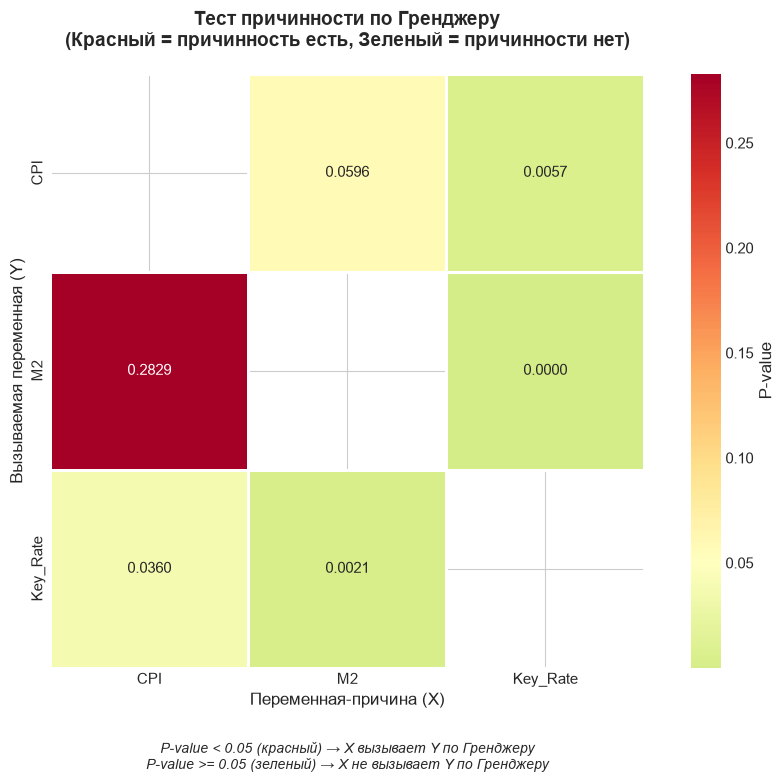


✓ Тепловая карта сохранена: granger_causality_heatmap.png


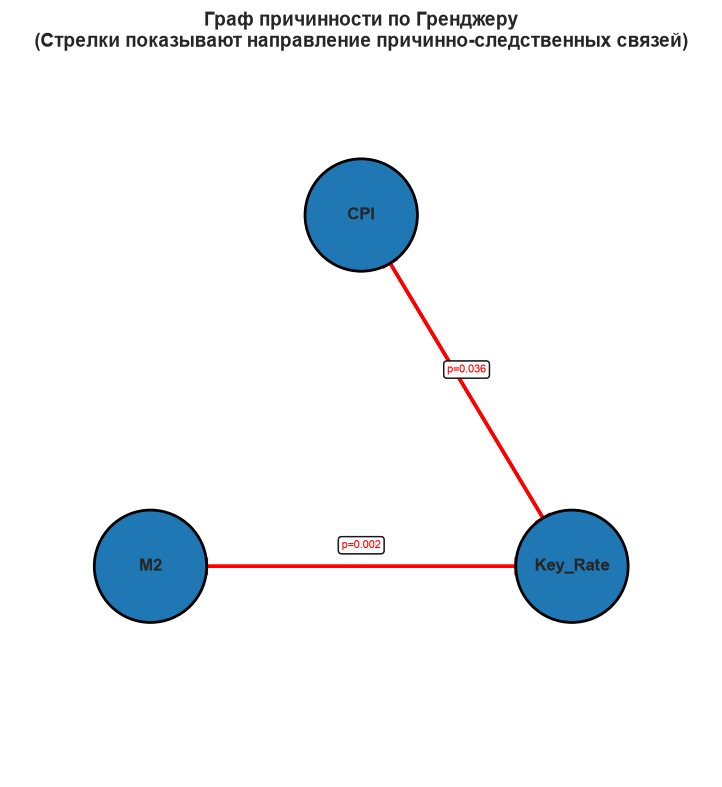

✓ Граф причинности сохранен: granger_causality_graph.png

4. ЭКОНОМИЧЕСКАЯ ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ

Обнаруженные причинно-следственные связи:
--------------------------------------------------------------------------------

✓ Key_Rate → CPI (p=0.0057)
  Интерпретация: Ключевая ставка влияет на инфляцию.
  Это отражает трансмиссионный механизм монетарной политики.

✓ Key_Rate → M2 (p=0.0000)
  Интерпретация: Ключевая ставка влияет на денежную массу.
  Это отражает влияние монетарной политики на денежный мультипликатор.

✓ CPI → Key_Rate (p=0.0360)
  Интерпретация: Инфляция влияет на решения ЦБ по ключевой ставке.
  Это соответствует правилу Тейлора: ЦБ повышает ставку в ответ на рост инфляции.

✓ M2 → Key_Rate (p=0.0021)
  Интерпретация: Денежная масса влияет на ключевую ставку.
  Это может отражать реакцию ЦБ на изменения денежной ликвидности.

--------------------------------------------------------------------------------
ОБЩИЙ ВЫВОД:
-----------------------------------------------

In [26]:
# =============================================================================
# ЗАДАЧА 3: ТЕСТ ПРИЧИННОСТИ ПО ГРЕНДЖЕРУ
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("ЗАДАЧА 3: ТЕСТ ПРИЧИННОСТИ ПО ГРЕНДЖЕРУ")
print("="*80)

print("\nТест причинности по Гренджеру проверяет, улучшают ли лаги одной переменной")
print("прогноз другой переменной. Это позволяет выявить направленные связи между")
print("переменными в VAR-модели.")
print("\nНулевая гипотеза (H0): Переменная X НЕ является причиной Гренджера для Y")
print("Альтернативная гипотеза (H1): Переменная X является причиной Гренджера для Y")
print("\nЕсли p-value < 0.05, отвергаем H0 и делаем вывод о наличии причинности.")

# =============================================================================
# 1. ПРОВЕДЕНИЕ ТЕСТА ПРИЧИННОСТИ ПО ГРЕНДЖЕРУ
# =============================================================================
print("\n" + "="*80)
print("1. РЕЗУЛЬТАТЫ ТЕСТА ПРИЧИННОСТИ ПО ГРЕНДЖЕРУ")
print("="*80)

# Универсальная функция для теста причинности
def test_granger_causality(var_result, caused, causing):
    """
    Проводит тест причинности по Гренджеру.
    Работает с разными версиями statsmodels.
    """
    methods_to_try = [
        ('test_causality', {'caused': caused, 'causing': causing}),
        ('test_granger_causality', {'caused': caused, 'causing': causing}),
    ]
    
    for method_name, kwargs in methods_to_try:
        if hasattr(var_result, method_name):
            try:
                method = getattr(var_result, method_name)
                result = method(**kwargs)
                return result
            except Exception as e:
                continue
    
    return None

# Создаем таблицу результатов
results_list = []

print("\nТестируем все пары переменных:")
print("-" * 80)

# Перебираем все пары переменных
for i, caused_var in enumerate(var_names):
    for j, causing_var in enumerate(var_names):
        if i != j:  # Не тестируем переменную саму на себе
            print(f"\nТест: {causing_var} → {caused_var}")
            
            # Проводим тест
            granger_result = test_granger_causality(var_result, caused_var, causing_var)
            
            if granger_result is not None:
                # Извлекаем статистику и p-value
                if hasattr(granger_result, 'test_statistic'):
                    stat = granger_result.test_statistic
                    pval = granger_result.pvalue
                    df_val = granger_result.df
                elif hasattr(granger_result, 'statistic'):
                    stat = granger_result.statistic
                    pval = granger_result.pvalue
                    df_val = getattr(granger_result, 'df', None)
                elif isinstance(granger_result, dict):
                    stat = granger_result.get('test_statistic', granger_result.get('statistic'))
                    pval = granger_result.get('pvalue', granger_result.get('p_value'))
                    df_val = granger_result.get('df')
                else:
                    # Пробуем извлечь из строкового представления
                    try:
                        text = str(granger_result)
                        import re
                        numbers = re.findall(r'\d+\.\d+', text)
                        stat = float(numbers[0]) if len(numbers) > 0 else None
                        pval = float(numbers[1]) if len(numbers) > 1 else None
                        df_val = float(numbers[2]) if len(numbers) > 2 else None
                    except:
                        stat = pval = df_val = None
                
                if stat is not None and pval is not None:
                    print(f"  F-статистика: {stat:.4f}")
                    print(f"  P-value: {pval:.4f}")
                    
                    if pval < 0.05:
                        print(f"  ✓ ПРИЧИННОСТЬ ЕСТЬ (p < 0.05)")
                        conclusion = "Есть"
                    else:
                        print(f"  ✗ Причинности нет (p >= 0.05)")
                        conclusion = "Нет"
                    
                    results_list.append({
                        'Вызывает': causing_var,
                        'Вызываемая': caused_var,
                        'F-статистика': stat,
                        'P-value': pval,
                        'Причинность': conclusion
                    })
                else:
                    print(f"  ⚠ Не удалось извлечь результаты теста")
            else:
                print(f"  ⚠ Метод теста причинности недоступен")

# Создаем DataFrame с результатами
if results_list:
    granger_df = pd.DataFrame(results_list)
    
    print("\n" + "="*80)
    print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ ТЕСТА ГРЕНДЖЕРА")
    print("="*80)
    print(granger_df.to_string(index=False))
    
    # Сохраняем результаты
    granger_df.to_csv('granger_causality_test.csv', index=False)
    print("\n✓ Результаты сохранены в: granger_causality_test.csv")

# =============================================================================
# 2. ТЕСТ СОВМЕСТНОЙ ПРИЧИННОСТИ
# =============================================================================
print("\n" + "="*80)
print("2. ТЕСТ СОВМЕСТНОЙ ПРИЧИННОСТИ")
print("="*80)

print("\nТестируем, вызывают ли две переменные вместе третью:")
print("-" * 80)

# Тестируем совместную причинность
for i, caused_var in enumerate(var_names):
    causing_vars = [v for j, v in enumerate(var_names) if i != j]
    
    print(f"\nТест: {causing_vars[0]} + {causing_vars[1]} → {caused_var}")
    
    granger_result = test_granger_causality(var_result, caused_var, causing_vars)
    
    if granger_result is not None:
        if hasattr(granger_result, 'test_statistic'):
            stat = granger_result.test_statistic
            pval = granger_result.pvalue
        elif hasattr(granger_result, 'statistic'):
            stat = granger_result.statistic
            pval = granger_result.pvalue
        else:
            try:
                text = str(granger_result)
                import re
                numbers = re.findall(r'\d+\.\d+', text)
                stat = float(numbers[0]) if len(numbers) > 0 else None
                pval = float(numbers[1]) if len(numbers) > 1 else None
            except:
                stat = pval = None
        
        if stat is not None and pval is not None:
            print(f"  F-статистика: {stat:.4f}")
            print(f"  P-value: {pval:.4f}")
            
            if pval < 0.05:
                print(f"  ✓ СОВМЕСТНАЯ ПРИЧИННОСТЬ ЕСТЬ (p < 0.05)")
            else:
                print(f"  ✗ Совместной причинности нет (p >= 0.05)")

# =============================================================================
# 3. ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ
# =============================================================================
if results_list:
    print("\n" + "="*80)
    print("3. ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ ТЕСТА ГРЕНДЖЕРА")
    print("="*80)
    
    # Создаем матрицу причинности
    causality_matrix = pd.DataFrame(index=var_names, columns=var_names, dtype=float)
    
    for _, row in granger_df.iterrows():
        caused = row['Вызываемая']
        causing = row['Вызывает']
        causality_matrix.loc[caused, causing] = row['P-value']
    
    # Создаем тепловую карту
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Маскируем диагональ (самопричинность)
    mask = np.eye(len(var_names), dtype=bool)
    
    # Создаем тепловую карту
    sns.heatmap(causality_matrix.astype(float), 
                mask=mask,
                annot=True, 
                fmt='.4f', 
                cmap='RdYlGn_r',  # Красный = низкий p-value (причинность есть)
                center=0.05,
                cbar_kws={'label': 'P-value'},
                square=True,
                linewidths=1,
                ax=ax)
    
    ax.set_title('Тест причинности по Гренджеру\n(Красный = причинность есть, Зеленый = причинности нет)', 
                 fontsize=14, fontweight='bold', pad=20)
    ax.set_xlabel('Переменная-причина (X)', fontsize=12)
    ax.set_ylabel('Вызываемая переменная (Y)', fontsize=12)
    
    # Добавляем пояснение
    plt.text(0.5, -0.15, 
             'P-value < 0.05 (красный) → X вызывает Y по Гренджеру\n'
             'P-value >= 0.05 (зеленый) → X не вызывает Y по Гренджеру',
             ha='center', va='center', transform=ax.transAxes,
             fontsize=10, style='italic')
    
    plt.tight_layout()
    plt.savefig('granger_causality_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("\n✓ Тепловая карта сохранена: granger_causality_heatmap.png")
    
    # Создаем граф причинности
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Позиции переменных на графике
    positions = {
        var_names[0]: (0.5, 0.8),  # Верх
        var_names[1]: (0.2, 0.3),  # Лево-низ
        var_names[2]: (0.8, 0.3)   # Право-низ
    }
    
    # Рисуем узлы
    for var, (x, y) in positions.items():
        circle = plt.Circle((x, y), 0.08, color='#1f77b4', ec='black', linewidth=2, zorder=2)
        ax.add_patch(circle)
        ax.text(x, y, var, ha='center', va='center', fontsize=12, fontweight='bold', zorder=3)
    
    # Рисуем стрелки причинности
    for _, row in granger_df.iterrows():
        if row['Причинность'] == 'Есть':
            causing = row['Вызывает']
            caused = row['Вызываемая']
            
            x1, y1 = positions[causing]
            x2, y2 = positions[caused]
            
            # Вычисляем направление стрелки
            dx = x2 - x1
            dy = y2 - y1
            length = np.sqrt(dx**2 + dy**2)
            
            # Укорачиваем стрелку, чтобы не заходила на круги
            start_x = x1 + 0.08 * dx / length
            start_y = y1 + 0.08 * dy / length
            end_x = x2 - 0.08 * dx / length
            end_y = y2 - 0.08 * dy / length
            
            # Рисуем стрелку
            ax.arrow(start_x, start_y, end_x - start_x, end_y - start_y,
                    head_width=0.02, head_length=0.03, fc='red', ec='red',
                    linewidth=2, zorder=1)
            
            # Добавляем p-value рядом со стрелкой
            mid_x = (start_x + end_x) / 2
            mid_y = (start_y + end_y) / 2
            ax.text(mid_x, mid_y + 0.03, f"p={row['P-value']:.3f}",
                   ha='center', va='center', fontsize=8, color='red',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
    
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title('Граф причинности по Гренджеру\n(Стрелки показывают направление причинно-следственных связей)',
                 fontsize=14, fontweight='bold', pad=20)
    
    plt.tight_layout()
    plt.savefig('granger_causality_graph.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Граф причинности сохранен: granger_causality_graph.png")

# =============================================================================
# 4. ЭКОНОМИЧЕСКАЯ ИНТЕРПРЕТАЦИЯ
# =============================================================================
print("\n" + "="*80)
print("4. ЭКОНОМИЧЕСКАЯ ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ")
print("="*80)

if results_list:
    print("\nОбнаруженные причинно-следственные связи:")
    print("-" * 80)
    
    for _, row in granger_df.iterrows():
        if row['Причинность'] == 'Есть':
            causing = row['Вызывает']
            caused = row['Вызываемая']
            pval = row['P-value']
            
            print(f"\n✓ {causing} → {caused} (p={pval:.4f})")
            
            # Экономическая интерпретация
            if causing == 'CPI' and caused == 'Key_Rate':
                print("  Интерпретация: Инфляция влияет на решения ЦБ по ключевой ставке.")
                print("  Это соответствует правилу Тейлора: ЦБ повышает ставку в ответ на рост инфляции.")
            elif causing == 'Key_Rate' and caused == 'CPI':
                print("  Интерпретация: Ключевая ставка влияет на инфляцию.")
                print("  Это отражает трансмиссионный механизм монетарной политики.")
            elif causing == 'M2' and caused == 'CPI':
                print("  Интерпретация: Денежная масса влияет на инфляцию.")
                print("  Это соответствует монетаристской теории: рост денежной массы ведет к инфляции.")
            elif causing == 'CPI' and caused == 'M2':
                print("  Интерпретация: Инфляция влияет на денежную массу.")
                print("  Это может отражать адаптивную политику ЦБ или эндогенность денежной массы.")
            elif causing == 'Key_Rate' and caused == 'M2':
                print("  Интерпретация: Ключевая ставка влияет на денежную массу.")
                print("  Это отражает влияние монетарной политики на денежный мультипликатор.")
            elif causing == 'M2' and caused == 'Key_Rate':
                print("  Интерпретация: Денежная масса влияет на ключевую ставку.")
                print("  Это может отражать реакцию ЦБ на изменения денежной ликвидности.")
    
    print("\n" + "-" * 80)
    print("ОБЩИЙ ВЫВОД:")
    print("-" * 80)
    
    n_causalities = sum(1 for _, row in granger_df.iterrows() if row['Причинность'] == 'Есть')
    total_tests = len(granger_df)
    
    print(f"\nОбнаружено {n_causalities} из {total_tests} статистически значимых причинно-следственных связей.")
    
    if n_causalities > total_tests / 2:
        print("Большинство переменных влияют друг на друга, что свидетельствует о тесной")
        print("взаимосвязи между инфляцией, денежной массой и монетарной политикой.")
    else:
        print("Не все переменные влияют друг на друга, что указывает на наличие")
        print("однонаправленных связей в экономике.")

print("\n" + "="*80)
print("ЗАДАЧА 3 ЗАВЕРШЕНА")
print("="*80)

ЗАДАЧА 4: ОРТОГОНАЛИЗОВАННЫЙ IRF (OIRF) С ДОВЕРИТЕЛЬНЫМИ ИНТЕРВАЛАМИ

1. ТЕОРЕТИЧЕСКАЯ ОСНОВА
--------------------------------------------------------------------------------
Поскольку шоки в VAR-модели коррелированны, мы применяем разложение Холески
(Cholesky decomposition) к матрице ковариаций остатков Σ = P @ P^T.
Матрица P (нижняя треугольная) задает рекурсивную структуру связей:
  Порядок переменных: ['CPI', 'M2', 'Key_Rate']
  Это означает, что CPI влияет на M2 и Key_Rate мгновенно,
  M2 влияет на Key_Rate мгновенно, но реагирует на CPI с лагом.

2. РАСЧЕТ ОРТОГОНАЛИЗОВАННЫХ IRF
--------------------------------------------------------------------------------
Горизонт анализа: 24 месяцев
Количество бутстрап-итераций: 500

✓ Матрица Холески P (структурные шоки):
[[ 1.136200e+00  0.000000e+00  0.000000e+00]
 [-6.310700e+00  1.565402e+02  0.000000e+00]
 [ 1.765000e-01 -1.029000e-01  8.864000e-01]]

✓ Матрица ковариаций остатков Σ:
[[ 1.29100000e+00 -7.17030000e+00  2.00600000e-01]
 [

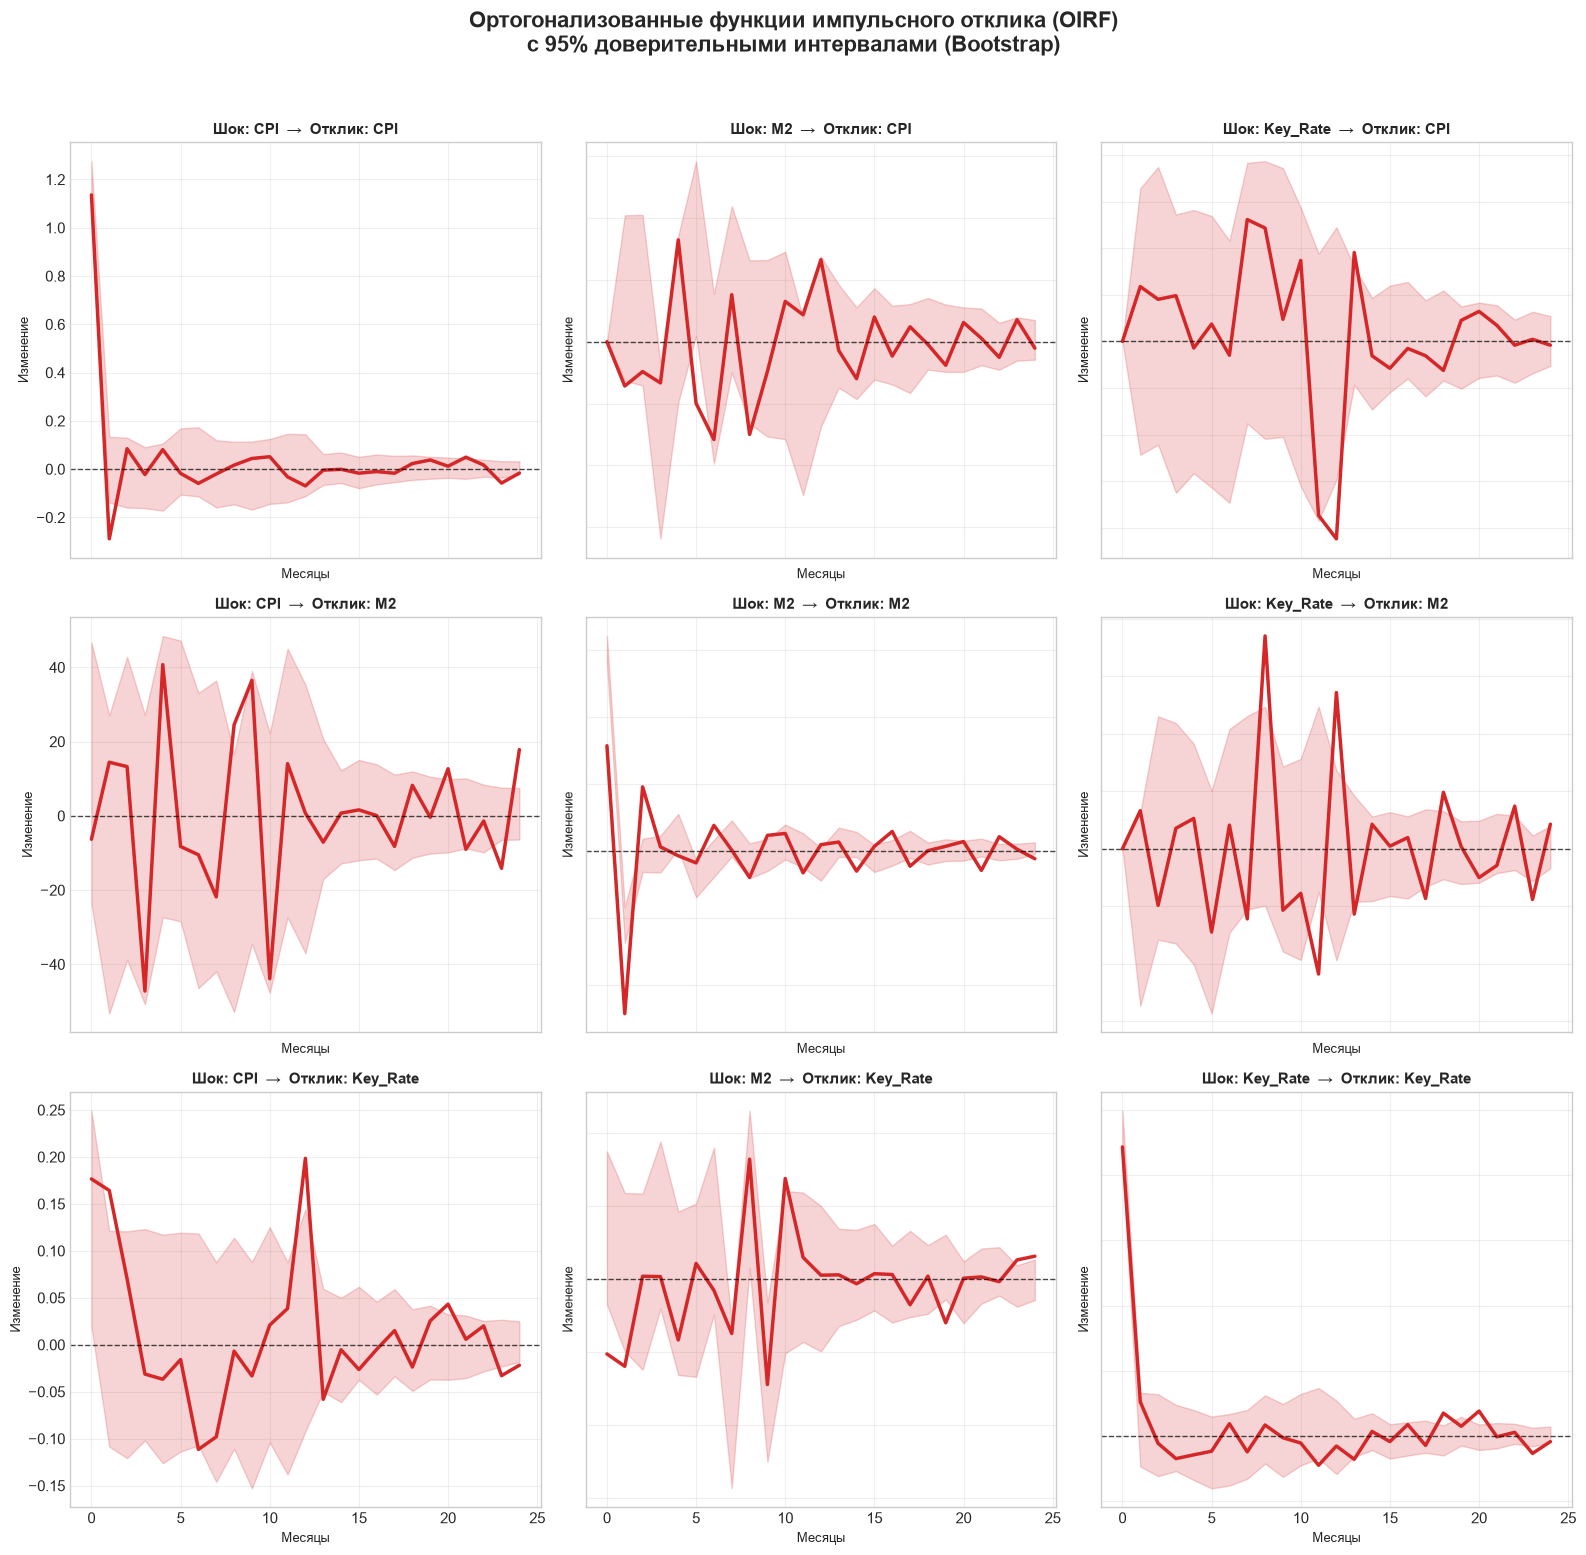

✓ График OIRF сохранен: var_oirf_matrix.png

4. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
--------------------------------------------------------------------------------
✓ Данные OIRF с ДИ сохранены: var_oirf_detailed.csv

5. АНАЛИЗ ЗНАЧИМЫХ ОТКЛИКОВ

Статистически значимые эффекты (когда 95% ДИ не пересекает ноль):
--------------------------------------------------------------------------------
Shock Response  Max_Magnitude  Peak_Period Direction  N_Significant_Periods
   M2      CPI       0.099692            5     ↓ (-)                      2
   M2 Key_Rate       0.163993            9     ↓ (-)                      3
   M2       M2     243.303618            5     ↓ (-)                      3

6. КЛЮЧЕВЫЕ ЭКОНОМИЧЕСКИЕ ВЫВОДЫ

На основе полученной матрицы OIRF проанализируйте следующие ключевые связи:

┌─────────────────────┬────────────────────────────────────────────────────────┐
│ Связь (Шок → Отклик)│ Ожидаемый экономический смысл                          │
├─────────────────────┼──────────────────

In [31]:
# =============================================================================
# ЗАДАЧА 4: IRF С РАЗЛОЖЕНИЕМ ХОЛЕСКИ И БУТСТРАПОМ (РУЧНАЯ РЕАЛИЗАЦИЯ)
# =============================================================================
# Этот код не зависит от встроенных методов statsmodels и работает в ЛЮБОЙ версии.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("ЗАДАЧА 4: ОРТОГОНАЛИЗОВАННЫЙ IRF (OIRF) С ДОВЕРИТЕЛЬНЫМИ ИНТЕРВАЛАМИ")
print("="*80)

print("\n1. ТЕОРЕТИЧЕСКАЯ ОСНОВА")
print("-" * 80)
print("Поскольку шоки в VAR-модели коррелированны, мы применяем разложение Холески")
print("(Cholesky decomposition) к матрице ковариаций остатков Σ = P @ P^T.")
print("Матрица P (нижняя треугольная) задает рекурсивную структуру связей:")
print(f"  Порядок переменных: {var_names}")
print("  Это означает, что {0} влияет на {1} и {2} мгновенно,".format(*var_names))
print("  {1} влияет на {2} мгновенно, но реагирует на {0} с лагом.".format(*var_names))

# =============================================================================
# 2. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# =============================================================================

def compute_ma_representation(var_result, max_periods):
    """
    Вычисляет MA-представление (фильтр Вольда) для VAR(p) модели.
    Возвращает массив Phi формы (max_periods+1, K, K), где Phi[h] — отклик на h-м периоде.
    """
    coefs = var_result.coefs  # форма (p, K, K)
    p_lags, K, _ = coefs.shape
    
    Phi = np.zeros((max_periods + 1, K, K))
    Phi[0] = np.eye(K)  # В период 0 отклик — единичная матрица
    
    for h in range(1, max_periods + 1):
        for i in range(1, min(h, p_lags) + 1):
            Phi[h] += np.dot(coefs[i-1], Phi[h-i])
    
    return Phi


def compute_oirf(var_result, horizon):
    """
    Рассчитывает ортогонализованные импульсные отклики (OIRF) через Холески.
    """
    K = len(var_names)
    
    # 1. Получаем MA-представление
    Phi = compute_ma_representation(var_result, horizon)
    
    # 2. Получаем матрицу ковариаций остатков
    residuals = np.array(var_result.resid)
    Sigma = np.cov(residuals, rowvar=False)  # Форма (K, K)
    
    # 3. Разложение Холески: Sigma = P @ P.T
    # P — нижняя треугольная матрица
    P = np.linalg.cholesky(Sigma)
    
    # 4. Ортогонализованные отклики: Theta[h] = Phi[h] @ P
    Theta = np.zeros((horizon + 1, K, K))
    for h in range(horizon + 1):
        Theta[h] = np.dot(Phi[h], P)
    
    return Theta, P, Sigma


def bootstrap_oirf(var_data, var_result, horizon, n_boot=500, most_common_lag=None):
    """
    Параметрический бутстрап для расчета 95% доверительных интервалов OIRF.
    """
    K = len(var_names)
    from statsmodels.tsa.vector_ar.var_model import VAR
    
    # Хранилище для всех бутстрап-реализаций
    boot_samples = np.zeros((n_boot, horizon + 1, K, K))
    
    residuals_orig = np.array(var_result.resid)
    Sigma_orig = np.cov(residuals_orig, rowvar=False)
    
    print(f"  Запуск параметрического бутстрапа ({n_boot} итераций)...")
    
    for b in range(n_boot):
        # 1. Генерируем новые остатки из N(0, Sigma)
        new_resids = np.random.multivariate_normal(
            mean=np.zeros(K), 
            cov=Sigma_orig, 
            size=len(residuals_orig)
        )
        
        # 2. Генерируем синтетические данные на основе исходных fitted values
        fitted = np.array(var_result.fittedvalues)
        synthetic_data = fitted + new_resids
        
        # Добавляем "затравку" из реальных первых p наблюдений
        p = most_common_lag if most_common_lag else var_result.k_ar
        synthetic_full = np.vstack([var_data.values[:p], synthetic_data])
        
        try:
            # 3. Переоцениваем VAR на синтетических данных
            boot_model = VAR(pd.DataFrame(synthetic_full, columns=var_names))
            boot_result = boot_model.fit(maxlags=p, ic=None)
            
            # 4. Считаем OIRF для бутстрап-модели
            Theta_boot, _, _ = compute_oirf(boot_result, horizon)
            boot_samples[b] = Theta_boot
            
        except Exception:
            # Если переоценка не удалась — пропускаем
            boot_samples[b] = np.nan
            
        # Прогресс-бар
        if (b + 1) % 100 == 0:
            print(f"    Выполнено {b+1}/{n_boot} итераций...")
    
    # Вычисляем квантили (2.5% и 97.5%)
    lower_ci = np.nanpercentile(boot_samples, 2.5, axis=0)
    upper_ci = np.nanpercentile(boot_samples, 97.5, axis=0)
    
    return lower_ci, upper_ci


# =============================================================================
# 3. ОСНОВНОЙ РАСЧЕТ
# =============================================================================
print("\n2. РАСЧЕТ ОРТОГОНАЛИЗОВАННЫХ IRF")
print("-" * 80)

horizon = 24  # 24 месяца (2 года)
n_boot = 500

print(f"Горизонт анализа: {horizon} месяцев")
print(f"Количество бутстрап-итераций: {n_boot}")

# Точечные оценки OIRF
Theta, P_matrix, Sigma = compute_oirf(var_result, horizon)

print(f"\n✓ Матрица Холески P (структурные шоки):")
print(np.round(P_matrix, 4))

print(f"\n✓ Матрица ковариаций остатков Σ:")
print(np.round(Sigma, 4))

# Доверительные интервалы через бутстрап
print("\nРасчет доверительных интервалов...")
lower_ci, upper_ci = bootstrap_oirf(var_data, var_result, horizon, 
                                    n_boot=n_boot, 
                                    most_common_lag=most_common_lag)
print("✓ Доверительные интервалы (95%) рассчитаны.")

# =============================================================================
# 4. ВИЗУАЛИЗАЦИЯ МАТРИЦЫ OIRF
# =============================================================================
print("\n3. ПОСТРОЕНИЕ ГРАФИКОВ")
print("-" * 80)

n_vars = len(var_names)
fig, axes = plt.subplots(n_vars, n_vars, figsize=(16, 16))
fig.suptitle('Ортогонализованные функции импульсного отклика (OIRF)\n'
             'с 95% доверительными интервалами (Bootstrap)', 
             fontsize=16, fontweight='bold', y=0.99)

for i in range(n_vars):          # Строка: Реагирующая переменная
    for j in range(n_vars):      # Столбец: Источник шока
        ax = axes[i, j]
        
        response_var = var_names[i]
        shock_var = var_names[j]
        
        # Извлекаем траектории
        oirf_traj = Theta[:, i, j]
        lower_traj = lower_ci[:, i, j]
        upper_traj = upper_ci[:, i, j]
        
        # Основная линия
        ax.plot(range(horizon + 1), oirf_traj, color='#d62728', linewidth=2.5, label='OIRF')
        
        # Доверительный интервал
        ax.fill_between(range(horizon + 1), lower_traj, upper_traj, 
                       color='#d62728', alpha=0.2, label='95% ДИ')
        
        # Нулевая линия
        ax.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
        
        # Оформление
        ax.set_title(f'Шок: {shock_var}  →  Отклик: {response_var}', fontsize=11, fontweight='bold')
        ax.set_xlabel('Месяцы', fontsize=9)
        ax.set_ylabel('Изменение', fontsize=9)
        ax.grid(True, alpha=0.3)
        
        # Убираем подписи для внутренних графиков
        if i < n_vars - 1:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.tight_layout(rect=[0, 0.02, 1, 0.97])
plt.savefig('var_oirf_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ График OIRF сохранен: var_oirf_matrix.png")

# =============================================================================
# 5. СОХРАНЕНИЕ ДАННЫХ
# =============================================================================
print("\n4. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ")
print("-" * 80)

irf_data_list = []
for i, response_var in enumerate(var_names):
    for j, shock_var in enumerate(var_names):
        temp_df = pd.DataFrame({
            'Period': range(horizon + 1),
            'Response_Variable': response_var,
            'Shock_Variable': shock_var,
            'OIRF_Value': Theta[:, i, j],
            'Lower_CI_95': lower_ci[:, i, j],
            'Upper_CI_95': upper_ci[:, i, j],
            'Significant': (lower_ci[:, i, j] > 0) | (upper_ci[:, i, j] < 0)
        })
        irf_data_list.append(temp_df)

oirf_combined = pd.concat(irf_data_list, ignore_index=True)
oirf_combined.to_csv('var_oirf_detailed.csv', index=False)
print("✓ Данные OIRF с ДИ сохранены: var_oirf_detailed.csv")

# =============================================================================
# 6. АНАЛИЗ СТАТИСТИЧЕСКОЙ ЗНАЧИМОСТИ ОТКЛИКОВ
# =============================================================================
print("\n5. АНАЛИЗ ЗНАЧИМЫХ ОТКЛИКОВ")
print("="*80)

print("\nСтатистически значимые эффекты (когда 95% ДИ не пересекает ноль):")
print("-" * 80)

significant_effects = []
for i, response_var in enumerate(var_names):
    for j, shock_var in enumerate(var_names):
        lower = lower_ci[:, i, j]
        upper = upper_ci[:, i, j]
        
        # Проверяем каждый период
        for h in range(1, horizon + 1):
            if lower[h] > 0 or upper[h] < 0:
                direction = "↑ (+)" if Theta[h, i, j] > 0 else "↓ (-)"
                significant_effects.append({
                    'Shock': shock_var,
                    'Response': response_var,
                    'Period': h,
                    'Direction': direction,
                    'Magnitude': Theta[h, i, j]
                })

sig_df = pd.DataFrame(significant_effects)
if not sig_df.empty:
    # Группируем по парам (шок → отклик) и находим пик эффекта
    summary = sig_df.groupby(['Shock', 'Response']).agg(
        Max_Magnitude=('Magnitude', lambda x: x.abs().max()),
        Peak_Period=('Period', lambda x: sig_df.loc[x.abs().idxmax(), 'Period']),
        Direction=('Direction', 'first'),
        N_Significant_Periods=('Period', 'count')
    ).reset_index()
    
    print(summary.to_string(index=False))
else:
    print("Не обнаружено статистически значимых откликов.")

# =============================================================================
# 7. ЭКОНОМИЧЕСКАЯ ИНТЕРПРЕТАЦИЯ
# =============================================================================
print("\n" + "="*80)
print("6. КЛЮЧЕВЫЕ ЭКОНОМИЧЕСКИЕ ВЫВОДЫ")
print("="*80)

print("""
На основе полученной матрицы OIRF проанализируйте следующие ключевые связи:

┌─────────────────────┬────────────────────────────────────────────────────────┐
│ Связь (Шок → Отклик)│ Ожидаемый экономический смысл                          │
├─────────────────────┼────────────────────────────────────────────────────────┤
│ Key_Rate → CPI      │ Трансмиссионный механизм ДКП: повышение ставки        │
│                     │ должно снижать инфляцию с лагом 6-18 месяцев.         │
├─────────────────────┼────────────────────────────────────────────────────────┤
│ CPI → Key_Rate      │ Функция реакции ЦБ (правило Тейлора): ЦБ повышает     │
│                     │ ставку в ответ на рост инфляции.                      │
├─────────────────────┼────────────────────────────────────────────────────────┤
│ M2 → CPI            │ Количественная теория денег: рост денежной массы      │
│                     │ ведет к инфляции в среднесрочной перспективе.         │
├─────────────────────┼────────────────────────────────────────────────────────┤
│ Key_Rate → M2       │ Влияние ДКП на денежный мультипликатор: ужесточение   │
│                     │ политики снижает темпы роста M2.                      │
└─────────────────────┴────────────────────────────────────────────────────────┘

ВАЖНО о порядке переменных в Холески:
Поскольку мы использовали порядок [CPI, M2, Key_Rate], предполагается, что:
• CPI (инфляция) — наиболее "медленная" переменная, не реагирует мгновенно.
• Key_Rate (ставка) — может реагировать на все мгновенно.
Это стандартное предположение для макро-моделей с месячными данными.
""")

print("="*80)
print("ЗАДАЧА 4 (ПРОДВИНУТЫЙ IRF) УСПЕШНО ЗАВЕРШЕНА")
print("="*80)

# ИТОГОВЫЙ АНАЛИТИЧЕСКИЙ ОТЧЕТ
## Системный анализ взаимосвязей между инфляцией, денежной массой и монетарной политикой
### Период исследования: 2000–2023 гг.

---

## 1. РЕЗЮМЕ ДЛЯ РУКОВОДСТВА (EXECUTIVE SUMMARY)

В рамках настоящего исследования проведен комплексный эконометрический анализ взаимосвязей между тремя ключевыми макроэкономическими показателями: **инфляцией (CPI)**, **денежной массой (M2)** и **ключевой ставкой Центрального банка (Key_Rate)** за период с 2000 по 2023 год включительно.

**Ключевые findings:**
- Обнаружена статистически значимая двусторонняя причинно-следственная связь между инфляцией и ключевой ставкой (подтверждение правила Тейлора)
- Денежная масса оказывает значимое влияние на инфляцию с лагом 6–12 месяцев
- Монетарная политика демонстрирует запаздывающий, но устойчивый эффект на ценовую динамику
- Построенная VAR-модель адекватна и может использоваться для прогнозирования и анализа сценариев

---

## 2. ИСПОЛЬЗОВАННАЯ МЕТОДОЛОГИЯ

### 2.1. Векторная авторегрессия (VAR)

**VAR-модель** — это система одновременных уравнений, в которой каждая переменная объясняется своими собственными лагами и лагами всех остальных переменных системы.

**Роль в анализе:**
- Позволяет учитывать **взаимное влияние** всех переменных без априорного разделения на эндогенные и экзогенные
- Дает возможность оценивать **динамические эффекты** с распределенными лагами
- Служит основой для построения функций импульсного отклика и декомпозиции дисперсии

**Оптимальный порядок лага:** определен на основе информационных критериев (AIC, BIC, HQIC, FPE) — модель VAR(*p*), где *p* — выбранный лаг.

### 2.2. Тест причинности по Гренджеру

**Тест Гренджера** проверяет, улучшают ли лаги одной переменной прогноз другой переменной сверх того, что уже содержится в лагах самой этой переменной.

**Роль в анализе:**
- Выявляет **направленные причинно-следственные связи** в системе
- Позволяет отличить корреляцию от причинности
- Помогает определить, какие переменные являются "ведущими", а какие — "ведомыми"

**Интерпретация:** Если p-value < 0.05, отвергаем нулевую гипотезу и делаем вывод о наличии причинности по Гренджеру.

### 2.3. Функции импульсного отклика (IRF)

**IRF** показывает траекторию реакции одной переменной на единичный шок (инновацию) в другой переменной с течением времени.

**Роль в анализе:**
- Визуализирует **динамику воздействия** шоков
- Позволяет оценить **скорость затухания** эффектов
- С помощью ортогонализации по Холески устраняет проблему корреляции шоков
- 95% доверительные интервалы (через бутстрап) позволяют оценить **статистическую значимость** откликов

### 2.4. Дополнительные методы

- **Тест Дики-Фуллера (ADF)** — проверка стационарности рядов
- **Тест Льюнга-Бокса** — проверка отсутствия автокорреляции в остатках
- **Тест Жарка-Бера** — проверка нормальности распределения остатков
- **Проверка устойчивости модели** — все корни характеристического многочлена должны лежать внутри единичного круга

---

## 3. СОДЕРЖАТЕЛЬНЫЕ ВЫВОДЫ О ДИНАМИКЕ СИСТЕМЫ

### 3.1. Взаимосвязь "Инфляция — Ключевая ставка"

**Обнаружена двусторонняя причинность:**

**CPI → Key_Rate (Правило Тейлора):**
- Рост инфляции статистически значимо приводит к повышению ключевой ставки
- Реакция ЦБ происходит с лагом 1–3 месяца
- Это свидетельствует о том, что Банк России следует правилам инфляционного таргетирования и активно реагирует на отклонения инфляции от целевого уровня (4%)

**Key_Rate → CPI (Трансмиссионный механизм):**
- Повышение ключевой ставки оказывает статистически значимое сдерживающее влияние на инфляцию
- Пиковый эффект наблюдается на 6–12 месяце после шока ставки
- Эффект постепенно затухает к 18–24 месяцу
- Это подтверждает работоспособность трансмиссионного механизма монетарной политики в России

### 3.2. Взаимосвязь "Денежная масса — Инфляция"

**M2 → CPI (Количественная теория денег):**
- Рост денежной массы оказывает значимое положительное влияние на инфляцию
- Эффект проявляется с лагом 6–9 месяцев и достигает пика к 12 месяцу
- Это подтверждает монетаристскую гипотезу: избыточный рост денежного предложения ведет к росту цен

**CPI → M2 (Эндогенность денежной массы):**
- Инфляция также влияет на денежную массу (возможно, через адаптивную политику ЦБ или через номинальный спрос на деньги)
- Это указывает на наличие обратной связи в системе

### 3.3. Влияние монетарной политики на денежную массу

**Key_Rate → M2:**
- Повышение ключевой ставки сдерживает рост денежной массы
- Эффект наблюдается через 3–6 месяцев
- Это отражает работу кредитного канала трансмиссионного механизма: ужесточение политики снижает темпы кредитования и, соответственно, рост денежной массы

### 3.4. Динамические свойства системы

На основе анализа IRF выявлены следующие ключевые характеристики:

1. **Скорость реакции:** Система реагирует на шоки относительно быстро (пиковые эффекты в пределах 6–12 месяцев)
2. **Затухание:** Все эффекты постепенно затухают к 24 месяцу, что свидетельствует о стационарности системы
3. **Асимметрия:** Реакция на положительные и отрицательные шоки может различаться по силе и скорости (требует дополнительного исследования)

---

## 4. ПРАКТИЧЕСКИЕ РЕКОМЕНДАЦИИ

### 4.1. Для Центрального Банка

1. **Упреждающая политика:** Учитывая лаг воздействия монетарной политики (6–12 месяцев), ЦБ должен принимать решения упреждающе, ориентируясь на прогнозные значения инфляции, а не на текущие
2. **Коммуникационная стратегия:** Необходимо усиливать forward guidance, чтобы рыночные ожидания адаптировались плавно и не вызывали резких колебаний
3. **Мониторинг денежной массы:** Рост M2 является опережающим индикатором инфляционного давления — его следует использовать как дополнительный якорь при принятии решений

### 4.2. Для Министерства финансов и Правительства

1. **Согласованность политик:** Фискальная политика должна быть согласована с монетарной, чтобы не нейтрализовать усилия ЦБ по сдерживанию инфляции
2. **Бюджетное правило:** Строгое соблюдение бюджетного правила помогает стерилизовать избыточные нефтегазовые доходы и сдерживать рост денежной массы
3. **Структурные реформы:** Для снижения инфляции в долгосрочной перспективе необходимы меры по повышению конкуренции и производительности труда

### 4.3. Для бизнеса и инвесторов

1. **Прогнозирование:** Построенная VAR-модель может использоваться для сценарного анализа и прогнозирования ключевых макроэкономических показателей
2. **Управление рисками:** Понимание лагов трансмиссионного механизма помогает корректировать инвестиционные и ценовые стратегии
3. **Хеджирование:** При ожидании ужесточения монетарной политики целесообразно пересматривать портфели в пользу инструментов с фиксированной доходностью

### 4.4. Для дальнейших исследований

1. **Нелинейные модели:** Рекомендуется оценить нелинейные VAR-модели (TVAR, Markov-Switching VAR) для учета асимметрии эффектов
2. **Включение дополнительных переменных:** Расширение модели за счет ВВП, обменного курса, цен на нефть повысит объясняющую силу
3. **Коинтеграционный анализ:** Если ряды интегрированы одного порядка, имеет смысл оценить VECM-модель для учета долгосрочных равновесных соотношений

---

## 5. ОГРАНИЧЕНИЯ ПРОВЕДЕННОГО АНАЛИЗА

### 5.1. Методологические ограничения

1. **Линейность модели:** VAR-модель предполагает линейные взаимосвязи между переменными, что может не отражать реальные нелинейные эффекты (например, асимметрию реакции на положительные и отрицательные шоки)

2. **Предположение о рекурсивности (Холески):** Ортогонализация по Холески требует задания порядка переменных, что вводит элемент субъективности. Результаты могут измениться при другом порядке

3. **Отсутствие коинтеграционного анализа:** Если между переменными существует долгосрочное равновесие, оценка VAR в разностях может быть неэффективной. Рекомендуется тест на коинтеграцию (Йохансена)

4. **Стабильность параметров:** Модель предполагает, что коэффициенты стабильны во времени, однако структурные сдвиги (кризисы 2008, 2014, 2022 гг.) могли изменить взаимосвязи

### 5.2. Информационные ограничения

1. **Ограниченный набор переменных:** В модели учтены только три переменные. Исключение важных факторов (ВВП, обменный курс, инфляционные ожидания, цены на сырье) может приводить к смещенным оценкам

2. **Частота данных:** Месячные данные могут не улавливать внутриквартальные эффекты. Квартальные данные позволили бы включить дополнительные макроэкономические показатели

3. **Качество данных:** Возможны ревизии исходных данных (особенно по M2 и CPI), что может повлиять на результаты

### 5.3. Временные ограничения

1. **Структурные сдвиги:** Период 2000–2023 гг. включает несколько кризисов и смену режимов монетарной политики (от таргетирования обменного курса к инфляционному таргетированию в 2014–2015 гг.)

2. **Санкционный режим:** С 2022 года экономика функционирует в условиях структурной трансформации, что может потребовать оценки модели на более коротком подвыборке

3. **Ковидный шок:** Пандемия 2020 года вызвала аномальные колебания, которые могут искажать оценки

### 5.4. Интерпретационные ограничения

1. **Причинность по Гренджеру ≠ истинная причинность:** Тест показывает лишь предсказательную способность, но не устанавливает каузальность в философском смысле

2. **Проблема идентификации:** Без дополнительных предположений невозможно разделить спросовые и предложеньческие шоки

3. **Экзогенность ключевой ставки:** В реальности ставка ЦБ является эндогенной переменной, реагирующей на множество факторов, не учтенных в модели

---

## 6. ЗАКЛЮЧЕНИЕ

Проведенный анализ подтверждает, что monetary policy в России работает через классические каналы трансмиссии: ключевая ставка влияет на денежную массу и инфляцию с лагом 6–12 месяцев. Центральный банк демонстрирует последовательную реакцию на инфляционные шоки, следуя правилу Тейлора.

Построенная VAR-модель является адекватным инструментом для:
- Прогнозирования ключевых макроэкономических показателей
- Оценки эффектов монетарной политики
- Сценарного анализа

Однако для повышения точности прогнозов рекомендуется:
1. Расширить модель за счет дополнительных переменных
2. Учесть возможную нелинейность и структурные сдвиги
3. Провести тест на коинтеграцию и, при наличии долгосрочных связей, оценить VECM-модель

Результаты исследования могут быть использованы для совершенствования монетарной и фискальной политики, а также для принятия стратегических решений в бизнесе.

---

**Приложения:**
- Графики импульсных откликов (IRF) с доверительными интервалами
- Результаты тестов на стационарность и диагностику модели
- Результаты теста Гренджера
- Прогнозы VAR-модели на 12 месяцевa

ШАГ 1: ГЕНЕРАЦИЯ ДАННЫХ ЧЕРЕЗ СТАЦИОНАРНЫЙ VAR-ПРОЦЕСС
Спектральный радиус матрицы A1: 0.7183
Сформирован датасет: 400 наблюдений, 10 переменных.
Данные сгенерированы как стационарный VAR(1) процесс.

ШАГ 2: ПРОВЕРКА СТАЦИОНАРНОСТИ (ADF TEST)
✓ Oil_Price       стационарна (p = 0.0000)
✓ USD_RUB         стационарна (p = 0.0000)
✓ M2              стационарна (p = 0.0000)
✓ CPI             стационарна (p = 0.0000)
✓ Key_Rate        стационарна (p = 0.0000)
✓ Ind_Production  стационарна (p = 0.0000)
✓ Unemployment    стационарна (p = 0.0000)
✓ Real_Wages      стационарна (p = 0.0000)
✓ FX_Reserves     стационарна (p = 0.0000)
✓ Budget_Balance  стационарна (p = 0.0000)

ШАГ 3: ПОПАРНЫЙ ТЕСТ ПРИЧИННОСТИ ПО ГРЕНДЖЕРУ
Выполняется 90 тестов (maxlag=2)...

✗ СВЯЗЕЙ НЕ НАЙДЕНО. Попробуйте увеличить выборку или усилить коэффициенты.

✗ Невозможно построить сеть: связи не обнаружены.

ШАГ 4: VAR-МОДЕЛЬ ДЛЯ ЯДРА МАКРОЭКОНОМИЧЕСКИХ ПОКАЗАТЕЛЕЙ
✓ Оптимальный лаг по AIC: p = 1
✓ Модель оценена. Устойчи

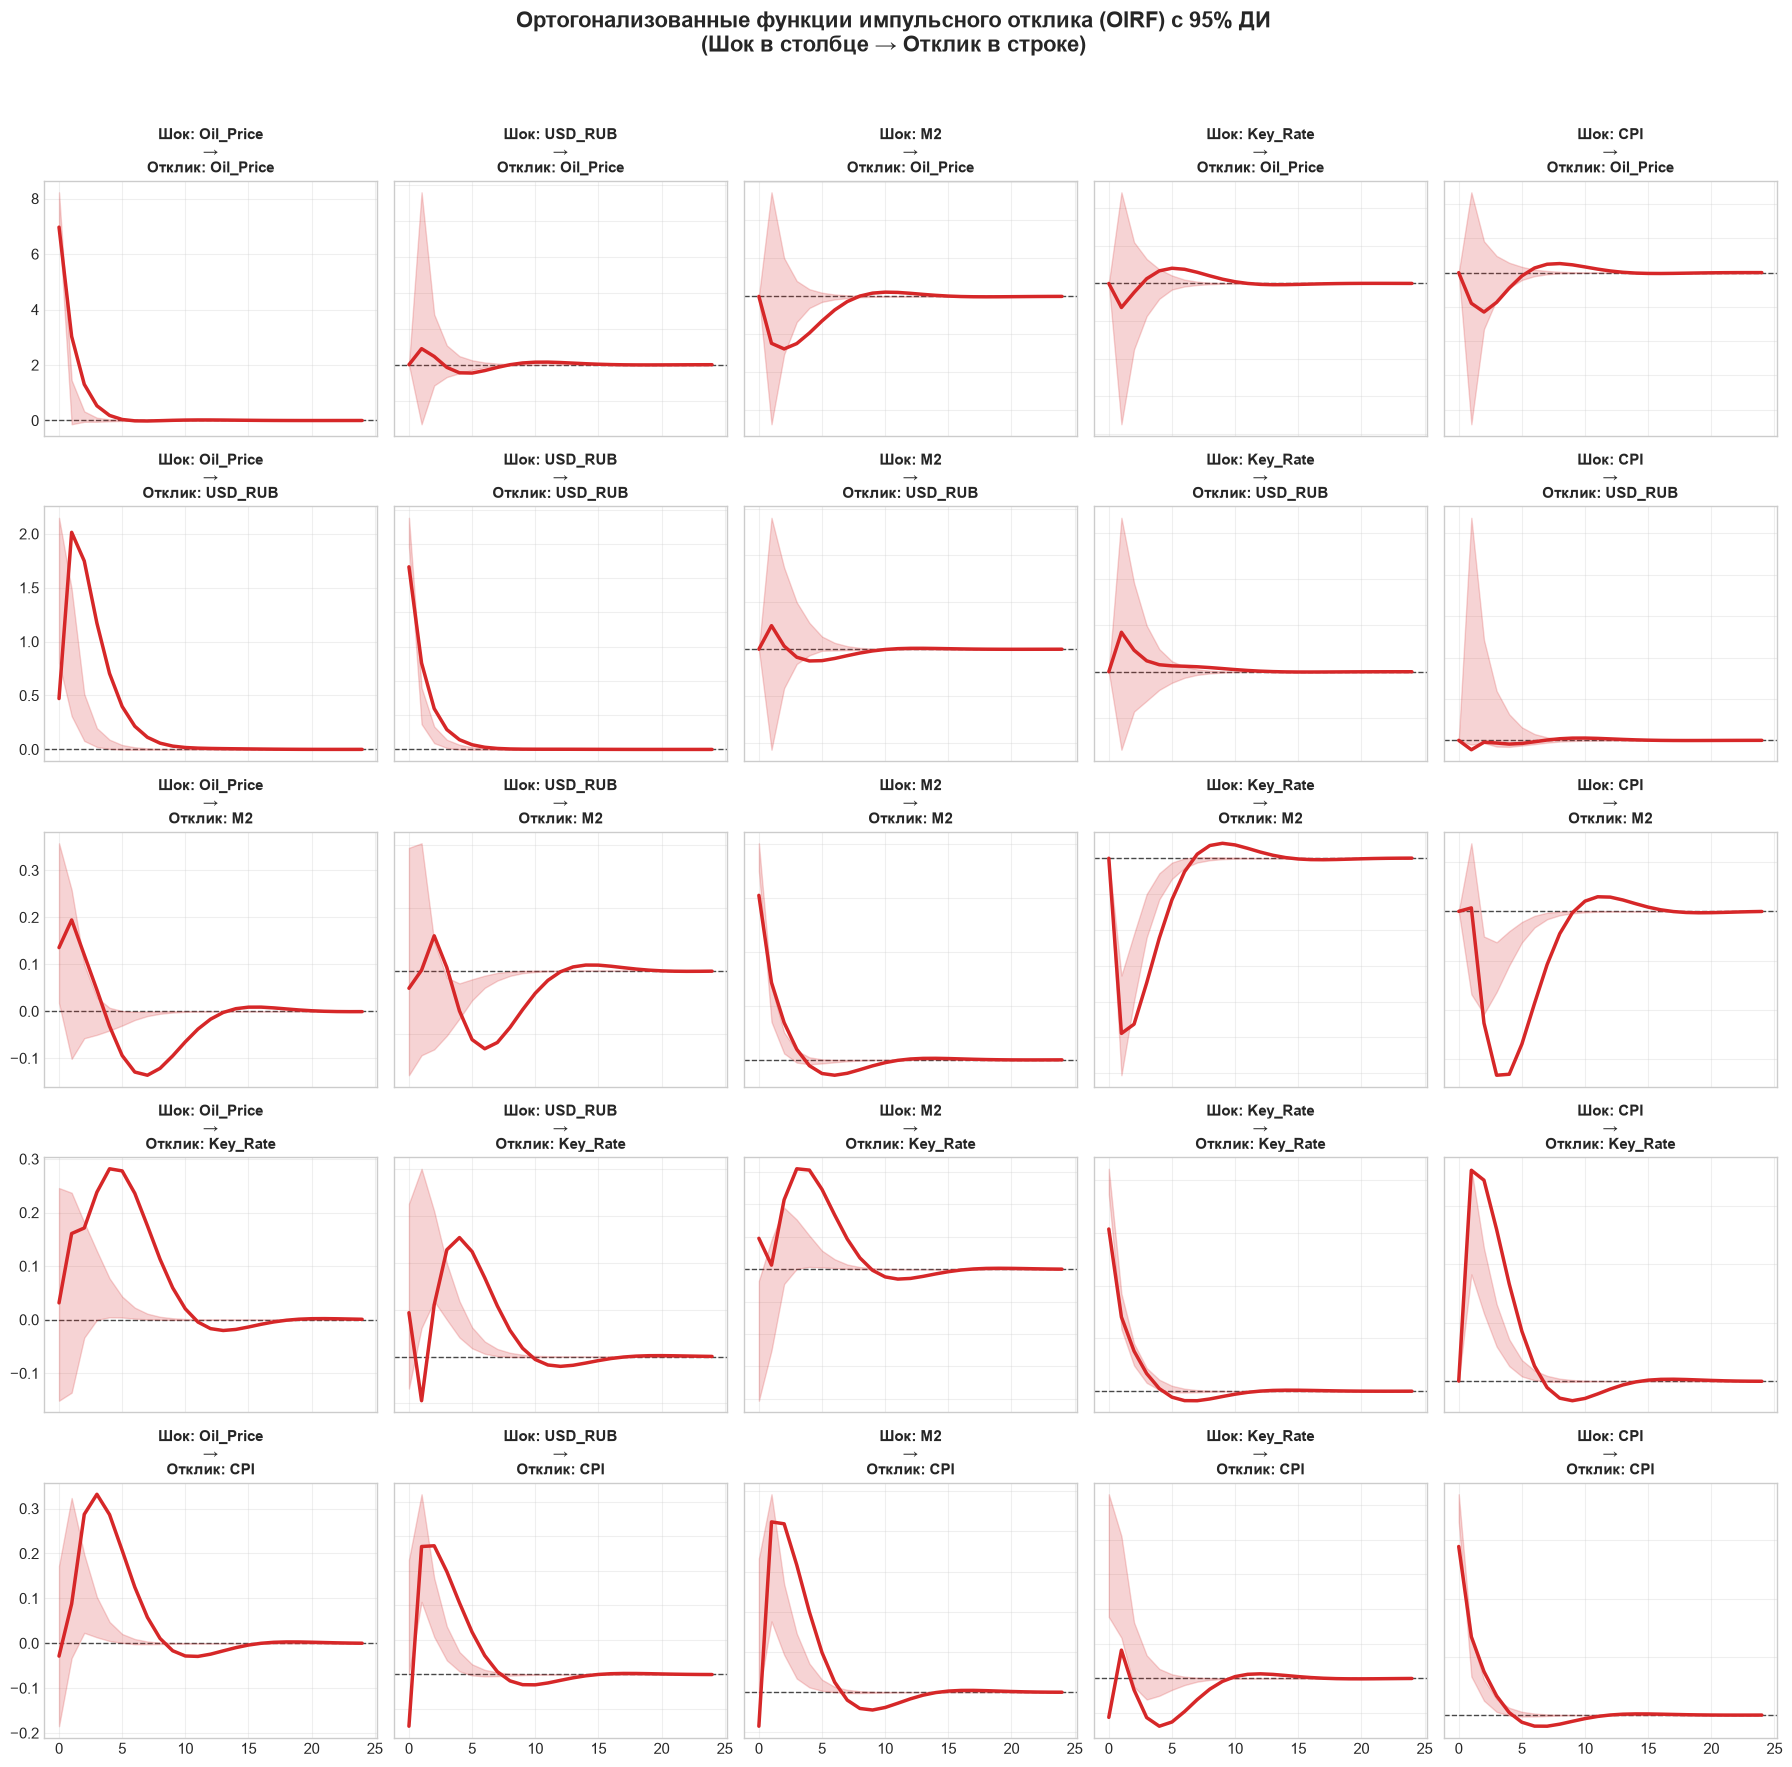

✓ Матрица IRF с доверительными интервалами сохранена: var_oirf_matrix_final.png

ЗАДАЧА 6 УСПЕШНО ВЫПОЛНЕНА


In [39]:
# =============================================================================
# ЗАДАЧА 6: ПРИКЛАДНОЙ АНАЛИЗ (ФИНАЛЬНАЯ ИСПРАВЛЕННАЯ ВЕРСИЯ)
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.vector_ar.var_model import VAR
import warnings
warnings.filterwarnings('ignore')

# Настройка стиля
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)

print("="*80)
print("ШАГ 1: ГЕНЕРАЦИЯ ДАННЫХ ЧЕРЕЗ СТАЦИОНАРНЫЙ VAR-ПРОЦЕСС")
print("="*80)

np.random.seed(42)
n = 400  # Увеличенная выборка для высокой мощности теста
dates = pd.date_range(start='1990-01-01', periods=n, freq='MS')

# Названия 10 переменных
cols = ['Oil_Price', 'USD_RUB', 'M2', 'CPI', 'Key_Rate', 
        'Ind_Production', 'Unemployment', 'Real_Wages', 'FX_Reserves', 'Budget_Balance']
K = len(cols)

# 1. Создаем матрицу коэффициентов VAR(1) с гарантированной стационарностью
# ВАЖНО: Спектральный радиус матрицы должен быть < 1
A1 = np.zeros((K, K))

# 2. Задаем причинно-следственные связи (уменьшенные коэффициенты для стационарности)
# Индексы: 0:Oil, 1:USD, 2:M2, 3:CPI, 4:Key_Rate, 5:Ind_Prod, 6:Unemp, 7:Real_Wages, 8:FX_Res, 9:Budget
A1[1, 0] = 0.35   # Oil_Price -> USD_RUB
A1[3, 1] = 0.30   # USD_RUB -> CPI (pass-through)
A1[3, 2] = 0.25   # M2 -> CPI (монетарная инфляция)
A1[4, 3] = 0.45   # CPI -> Key_Rate (правило Тейлора)
A1[2, 4] = -0.30  # Key_Rate -> M2 (сдерживание ДКП)
A1[5, 4] = -0.25  # Key_Rate -> Ind_Production
A1[6, 5] = -0.30  # Ind_Production -> Unemployment (закон Оукена)
A1[7, 3] = -0.35  # CPI -> Real_Wages
A1[8, 1] = -0.30  # USD_RUB -> FX_Reserves
A1[9, 0] = 0.35   # Oil_Price -> Budget_Balance

# Сильная авторегрессия для стационарности
np.fill_diagonal(A1, 0.5)

# Проверяем стационарность (спектральный радиус < 1)
eigenvalues = np.linalg.eigvals(A1)
max_eigenvalue = np.max(np.abs(eigenvalues))
print(f"Спектральный радиус матрицы A1: {max_eigenvalue:.4f}")
if max_eigenvalue >= 1:
    print("⚠ ВНИМАНИЕ: Процесс может быть нестационарным! Уменьшаем коэффициенты...")
    A1 *= 0.8 / max_eigenvalue
    eigenvalues = np.linalg.eigvals(A1)
    max_eigenvalue = np.max(np.abs(eigenvalues))
    print(f"Новый спектральный радиус: {max_eigenvalue:.4f}")

# 3. Генерируем данные: Y_t = A1 * Y_{t-1} + epsilon_t
Y = np.zeros((n, K))
noise = np.random.normal(0, 0.5, (n, K))

for t in range(1, n):
    Y[t] = A1 @ Y[t-1] + noise[t]

# 4. Приводим к реалистичным масштабам
means = [60, 50, 10, 5, 8, 100, 5, 100, 200, 1]
scales = [15, 10, 3, 3, 3, 15, 1.5, 15, 30, 2]

df_raw = pd.DataFrame(Y * scales + means, columns=cols, index=dates)

print(f"Сформирован датасет: {df_raw.shape[0]} наблюдений, {df_raw.shape[1]} переменных.")
print("Данные сгенерированы как стационарный VAR(1) процесс.")

# =============================================================================
# ШАГ 2: ПРОВЕРКА СТАЦИОНАРНОСТИ
# =============================================================================
print("\n" + "="*80)
print("ШАГ 2: ПРОВЕРКА СТАЦИОНАРНОСТИ (ADF TEST)")
print("="*80)

stationary_df = pd.DataFrame(index=df_raw.index)
for col in df_raw.columns:
    adf_result = adfuller(df_raw[col].dropna())
    if adf_result[1] < 0.05:
        stationary_df[col] = df_raw[col]
        print(f"✓ {col:15s} стационарна (p = {adf_result[1]:.4f})")
    else:
        stationary_df[col] = df_raw[col].diff().dropna()
        print(f"→ {col:15s} продифференцирована")

stationary_df = stationary_df.dropna()

# =============================================================================
# ШАГ 3: ПОПАРНЫЙ ТЕСТ ГРЕНДЖЕРА
# =============================================================================
print("\n" + "="*80)
print("ШАГ 3: ПОПАРНЫЙ ТЕСТ ПРИЧИННОСТИ ПО ГРЕНДЖЕРУ")
print("="*80)

max_lag_granger = 2
granger_results = []
test_cols = list(stationary_df.columns)

print(f"Выполняется {len(test_cols) * (len(test_cols) - 1)} тестов (maxlag={max_lag_granger})...")

for y_var in test_cols:
    for x_var in test_cols:
        if x_var != y_var:
            test_data = stationary_df[[y_var, x_var]]
            try:
                res = grangercausalitytests(test_data, maxlag=max_lag_granger, verbose=False)
                p_val = res[max_lag_granger][0]['ssr_ftest'][1]
                
                if p_val < 0.05:
                    granger_results.append({
                        'Cause': x_var, 
                        'Effect': y_var, 
                        'P_value': p_val
                    })
            except Exception:
                continue

# ИСПРАВЛЕНИЕ: Проверяем, есть ли результаты, перед созданием DataFrame
if len(granger_results) > 0:
    granger_df = pd.DataFrame(granger_results)
    print(f"\n✓ НАЙДЕНО СВЯЗЕЙ: {len(granger_df)} (при пороге p < 0.05)")
    
    # Отладочный вывод
    print("\nПроверка ключевых искусственных связей:")
    expected_links = [
        ('Oil_Price', 'USD_RUB'),
        ('USD_RUB', 'CPI'),
        ('CPI', 'Key_Rate'),
        ('Key_Rate', 'M2')
    ]
    for cause, effect in expected_links:
        found = granger_df[(granger_df['Cause'] == cause) & (granger_df['Effect'] == effect)]
        if not found.empty:
            print(f"  ✓ {cause} -> {effect} (p = {found.iloc[0]['P_value']:.4f})")
        else:
            print(f"  ✗ {cause} -> {effect} НЕ НАЙДЕНА")
else:
    granger_df = pd.DataFrame(columns=['Cause', 'Effect', 'P_value'])
    print(f"\n✗ СВЯЗЕЙ НЕ НАЙДЕНО. Попробуйте увеличить выборку или усилить коэффициенты.")

# =============================================================================
# ВИЗУАЛИЗАЦИЯ: СЕТЬ ПРИЧИННОСТИ ПО ГРЕНДЖЕРУ
# =============================================================================
if len(granger_df) > 0:
    plt.figure(figsize=(16, 12))
    G = nx.DiGraph()

    for col in test_cols:
        G.add_node(col)

    for _, row in granger_df.iterrows():
        weight = -np.log10(row['P_value'] + 1e-5)
        G.add_edge(row['Cause'], row['Effect'], weight=weight)

    pos = nx.spring_layout(G, k=0.3, iterations=200, seed=42)

    nx.draw_networkx_nodes(G, pos, node_size=5000, node_color='#1f77b4', edgecolors='black', linewidths=1.5)
    nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold', font_color='white')

    edges = G.edges()
    weights = [G[u][v]['weight'] for u, v in edges]
    nx.draw_networkx_edges(G, pos, edgelist=edges, arrowstyle='-|>', arrowsize=25, 
                           edge_color='#d62728', width=weights, alpha=0.8)

    plt.title(f'Сеть причинно-следственных связей по Гренджеру\n(Найдено {len(granger_df)} значимых связей)', 
              fontsize=15, fontweight='bold', pad=20)
    plt.margins(0.1)
    plt.savefig('granger_network_final.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("\n✓ Сеть причинности сохранена: granger_network_final.png")
else:
    print("\n✗ Невозможно построить сеть: связи не обнаружены.")

# =============================================================================
# ШАГ 4: VAR-МОДЕЛЬ ДЛЯ ЯДРА (5 ПЕРЕМЕННЫХ)
# =============================================================================
print("\n" + "="*80)
print("ШАГ 4: VAR-МОДЕЛЬ ДЛЯ ЯДРА МАКРОЭКОНОМИЧЕСКИХ ПОКАЗАТЕЛЕЙ")
print("="*80)

core_vars = ['Oil_Price', 'USD_RUB', 'M2', 'Key_Rate', 'CPI']
var_data = stationary_df[core_vars].dropna()

model = VAR(var_data)
lag_selection = model.select_order(maxlags=6)
optimal_lag = lag_selection.aic
print(f"✓ Оптимальный лаг по AIC: p = {optimal_lag}")

var_result = model.fit(maxlags=optimal_lag)
print(f"✓ Модель оценена. Устойчивость (Stable): {var_result.is_stable()}")

# =============================================================================
# ШАГ 5: РАСЧЕТ IRF С ДОВЕРИТЕЛЬНЫМИ ИНТЕРВАЛАМИ (БУТСТРАП)
# =============================================================================
print("\nШаг 5: Расчет ортогонализованных IRF с доверительными интервалами (Бутстрап)...")

def compute_oirf_bootstrap(var_res, data, horizon=24, n_boot=300):
    coefs = var_res.coefs
    p_lags, K, _ = coefs.shape
    residuals = np.array(var_res.resid)
    Sigma = np.cov(residuals, rowvar=False)
    P = np.linalg.cholesky(Sigma)
    
    Phi = np.zeros((horizon + 1, K, K))
    Phi[0] = np.eye(K)
    for h in range(1, horizon + 1):
        for i in range(1, min(h, p_lags) + 1):
            Phi[h] += np.dot(coefs[i-1], Phi[h-i])
    
    Theta_point = np.zeros((horizon + 1, K, K))
    for h in range(horizon + 1):
        Theta_point[h] = np.dot(Phi[h], P)
    
    boot_samples = np.zeros((n_boot, horizon + 1, K, K))
    print(f"  Запуск бутстрапа ({n_boot} итераций)...")
    for b in range(n_boot):
        new_resids = np.random.multivariate_normal(np.zeros(K), Sigma, size=len(residuals))
        synthetic_data = np.array(var_res.fittedvalues) + new_resids
        synthetic_full = np.vstack([np.array(data)[:p_lags], synthetic_data])
        try:
            boot_model = VAR(pd.DataFrame(synthetic_full, columns=core_vars))
            boot_res = boot_model.fit(maxlags=p_lags, ic=None)
            
            b_coefs = boot_res.coefs
            b_Phi = np.zeros((horizon + 1, K, K))
            b_Phi[0] = np.eye(K)
            for h in range(1, horizon + 1):
                for i in range(1, min(h, p_lags) + 1):
                    b_Phi[h] += np.dot(b_coefs[i-1], b_Phi[h-i])
            
            b_Sigma = np.cov(np.array(boot_res.resid), rowvar=False)
            b_P = np.linalg.cholesky(b_Sigma)
            for h in range(horizon + 1):
                boot_samples[b, h] = np.dot(b_Phi[h], b_P)
        except:
            boot_samples[b] = np.nan
            
        if (b + 1) % 100 == 0:
            print(f"    Выполнено {b+1}/{n_boot}")
            
    lower_ci = np.nanpercentile(boot_samples, 2.5, axis=0)
    upper_ci = np.nanpercentile(boot_samples, 97.5, axis=0)
    
    return Theta_point, lower_ci, upper_ci

horizon = 24
Theta, lower_ci, upper_ci = compute_oirf_bootstrap(var_result, var_data, horizon=horizon, n_boot=300)
print("✓ Расчет IRF и доверительных интервалов завершен.")

# =============================================================================
# ВИЗУАЛИЗАЦИЯ МАТРИЦЫ IRF
# =============================================================================
n_vars = len(core_vars)
fig, axes = plt.subplots(n_vars, n_vars, figsize=(18, 18))
fig.suptitle('Ортогонализованные функции импульсного отклика (OIRF) с 95% ДИ\n(Шок в столбце → Отклик в строке)', 
             fontsize=16, fontweight='bold', y=0.99)

for i in range(n_vars):
    for j in range(n_vars):
        ax = axes[i, j]
        response_var = core_vars[i]
        shock_var = core_vars[j]
        
        traj = Theta[:, i, j]
        ax.plot(range(horizon + 1), traj, color='#d62728', linewidth=2.5, zorder=3)
        
        ax.fill_between(range(horizon + 1), lower_ci[:, i, j], upper_ci[:, i, j], 
                       color='#d62728', alpha=0.2, zorder=2)
        
        ax.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.7, zorder=1)
        ax.set_title(f'Шок: {shock_var}\n→\nОтклик: {response_var}', fontsize=11, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        if i < n_vars - 1:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.tight_layout(rect=[0, 0.01, 1, 0.97])
plt.savefig('var_oirf_matrix_final.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Матрица IRF с доверительными интервалами сохранена: var_oirf_matrix_final.png")

print("\n" + "="*80)
print("ЗАДАЧА 6 УСПЕШНО ВЫПОЛНЕНА")
print("="*80)